# IMDB Movie Review Sentiment Classification
## Model development, generalisation, and evaluation

This study investigates how a small neural network can classify movie reviews as
positive or negative. We start with a simple baseline, study overfitting, and gradually
adjust the model. Each stage uses validation results to choose the starting point for
the next stage. The aim is to understand the effects of these choices, not just to report
one high accuracy score.

The implementation uses PyTorch, PyTorch Lightning, TorchMetrics, and scikit-learn.
The experiment follows the structure of the earlier coursework, while adding reliable
saving, common comparison metrics, and a final check across several random seeds.

**Run status:** this notebook was executed in full mode on Google Colab (Tesla T4 GPU,
PyTorch 2.14.1, run tag `imdb_classification_v02_run01`). All outputs below come from that
run. The observations and the conclusion were written afterwards, based on these outputs.

### Summary of the result

| | Selected model | Baseline (Model_01) |
|---|---|---|
| Hidden layer | 16 units, ReLU | 4 units, ReLU |
| Regularisation | Dropout 0.5, L2 = 0.0001 | none |
| Optimiser | RMSprop, learning rate 0.0002 | RMSprop, learning rate 0.001 |
| Final training | 15 epochs on 25,000 reviews | 7 epochs on 25,000 reviews |
| **Test accuracy** | **0.8908** | 0.8855 |
| Test F1 (positive class) | 0.8903 | 0.8834 |
| Test ROC AUC | 0.9554 | 0.9518 |

### How to run again

1. Open this notebook in Google Colab and select a GPU runtime if available.
2. For a first technical check, set `RUN_MODE = "smoke"`. For the study, use `"full"`.
3. Choose **Run all**. Missing supporting packages are installed when possible. Approve
   the Google Drive mount when Colab asks. No model-provider API key is needed.
4. In full mode, the final test runs automatically when `RUN_FINAL_TEST=True` and all
   required earlier stages have completed. Set it to `False` for a validation-only run.
5. Download this notebook with its outputs and the result ZIP from the displayed Drive path.

After a disconnection, use the same run tag and configuration. Completed experiments are
verified and reused. A new GPU is recorded rather than treated as a new experiment.
Do not run two sessions into the same output folder at the same time.

## Workflow

1. Define the task, data, and measure of success.
2. Prepare and inspect the reviews, including duplicate checks.
3. Build a baseline and explore model capacity.
4. Tune the learning rate and examine longer training.
5. Study L1, L2, combined regularisation, Dropout, and early stopping.
6. Compare loss functions, activations, momentum, optimisers, and depth.
7. Run a small grid search around the selected settings.
8. Repeat a few finalists with different seeds.
9. Fix the final settings, retrain, and evaluate the selected model and baseline.
10. Interpret the results and discuss the limitations.


## 1. Define the task

The task is binary sentiment classification. Given a movie review, the model predicts
whether it is positive or negative. Good training performance is not enough: we want
the model to perform well on reviews that were not used to fit its weights.

We use multi-hot word features and fully connected layers. This is a small classification
study, not a language-generation task or a large language model experiment.


## 2. Dataset and evaluation design

The IMDB archive contains 25,000 official training reviews and 25,000 official test
reviews, labelled 0 for negative and 1 for positive. We keep its existing word index
and use the 10,000-word limit from the coursework.

To preserve the earlier data split, we follow the archive loader's shuffle with seed 113.
The first 10,000 shuffled training rows form the validation set; the remaining 15,000
are used for fitting. scikit-learn performs this fixed split without another shuffle.
The split is not newly stratified; its class counts are reported in Section 4.4.

The test data may be inspected for size, class counts, and encoded-sequence overlap, but
no candidate model is scored on it during development. Final model and baseline settings
are saved before either final test evaluation.

**Important limitation:** the original coursework already used this test set repeatedly.
This workflow prevents further test-based selection, but it cannot make the historical
test set untouched again. These results are not a new independent benchmark.

## 3. Measure of success

The main metric is accuracy. We first compare with a majority-class baseline. Candidate
models are then selected using validation results, not test results.

- **Checkpoint within a run:** highest validation accuracy; ties use the earliest epoch.
- **Candidates within a stage:** higher selected-checkpoint accuracy, then lower common
  BCE from that same checkpoint, then the experiment name for a stable final tie-break.
- **Early stopping:** validation accuracy, with patience 3 and no minimum improvement.
- **Finalists across seeds:** higher mean selected-checkpoint accuracy, then lower mean
  BCE, then the name. We do not select the luckiest individual seed.

All models report BCE, including models trained with MSE. MSE and BCE are not compared
directly. Training loss with a regularisation penalty is also kept separate from data loss.


## 4. Prepare the data
### 4.1 Run controls and packages

The defaults below allow a full **Run all**, including final testing. Change only `RUN_MODE`
to `"smoke"` for a technical check: it uses 512 training / 256 validation rows, at most two
epochs per experiment, and only two grid entries. Smoke mode skips multi-seed confirmation
and final testing. Its results must not be used as study findings.

Use a new run tag when changing the code, split, or scientific settings. Package preparation
uses the runtime's existing PyTorch installation rather than replacing its CUDA stack.
If a package import still fails after installation, restart the runtime and run again.
No fixed training-time estimate is promised.


In [13]:
from pathlib import Path
import copy, gc, hashlib, importlib, importlib.metadata, importlib.util
import json, math, os, platform, random, re, subprocess, sys, time, uuid, warnings, zipfile
from datetime import datetime, timezone

RUN_MODE = "full"                      # "full" or "smoke"
RUN_FINAL_TEST = True                  # automatic at the end of a full run
RUN_SEED_CONFIRMATION = True           # repeat two finalists, not all experiments
AUTO_INSTALL = True
USE_GOOGLE_DRIVE = True
ALLOW_SOFTWARE_CHANGE = False          # inspect a software difference before opting in
RUN_TAG = "imdb_classification_v02_run01"
STUDY_VERSION = "imdb_classification_coursework_v02"
SEED = 23
EXTRA_SEEDS = [42, 77]
FINAL_SEED = 2026
VOCAB_SIZE = 10_000
SHORTLIST_SIZE = 2
MAX_EPOCHS = 20

assert RUN_MODE in {"full", "smoke"}
assert re.fullmatch(r"[A-Za-z0-9_-]+", RUN_TAG)
assert SEED not in EXTRA_SEEDS and len(set(EXTRA_SEEDS)) == len(EXTRA_SEEDS)
if importlib.util.find_spec("torch") is None:
    raise RuntimeError("Use a Colab runtime that provides PyTorch. This notebook will not replace the CUDA stack.")

requirements = {"lightning": "lightning>=2.2,<3", "torchmetrics": "torchmetrics>=1.3,<2",
                "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
                "sklearn": "scikit-learn", "packaging": "packaging>=23"}
missing = [spec for module, spec in requirements.items() if importlib.util.find_spec(module) is None]
if missing:
    if not AUTO_INSTALL:
        raise RuntimeError(f"Missing packages: {missing}. Enable AUTO_INSTALL or install them first.")
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
    importlib.invalidate_caches()

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import Dataset, DataLoader
import lightning.pytorch as pl
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
from lightning.pytorch.loggers import CSVLogger
from torchmetrics.classification import BinaryAccuracy
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, log_loss, roc_auc_score)
from packaging.version import Version
from IPython.display import display

if not (Version("2.2") <= Version(importlib.metadata.version("lightning")) < Version("3")):
    raise RuntimeError("This draft expects Lightning >=2.2,<3. Install a compatible version and restart.")
torch.set_float32_matmul_precision("highest")
torch.use_deterministic_algorithms(True, warn_only=True)
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
print({"mode": RUN_MODE, "torch": torch.__version__,
       "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
       "final_test_will_run": RUN_MODE == "full" and RUN_FINAL_TEST})


{'mode': 'full', 'torch': '2.14.1+cu130', 'device': 'Tesla T4', 'final_test_will_run': True}


### 4.2 Persistent files and environment records

Study settings and environment details are stored separately. A GPU change creates a
warning and a new session record, not a new scientific run. A change in Python, PyTorch,
Lightning, TorchMetrics, NumPy, or scikit-learn stops new training unless you explicitly
allow it. Allowing a change is not a promise of checkpoint compatibility or identical results.
Previous results and their original environment records are never relabelled as new runs.

Data files, committed checkpoints, stage results, and completed result files are checked
with SHA-256. JSON records carry a checksum of their contents. Active CSV logs are still
changing, so they are sealed when the trial completes; they are not used for recovery.
The final file inventory covers the saved run files, except the inventory itself.
Hashes detect file changes, not whether a result is scientifically correct or maliciously
altered together with its manifest.


In [14]:
if USE_GOOGLE_DRIVE:
    try:
        from google.colab import drive
    except ImportError as exc:
        raise RuntimeError("Drive mode needs Colab. For a local run set USE_GOOGLE_DRIVE=False.") from exc
    if not Path("/content/drive/MyDrive").is_dir():
        drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/IMDB_Classification_Coursework")
else:
    ROOT = Path.cwd() / "imdb_classification_outputs"
    warnings.warn("Local runtime storage may disappear when the Colab session ends.")

RUN_DIR = ROOT / "runs" / f"{RUN_TAG}_{RUN_MODE}"
DATA_DIR = ROOT / "data"
RUN_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)
SESSION_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ") + "_" + uuid.uuid4().hex[:8]
SESSION_DIR = RUN_DIR / "sessions" / SESSION_ID
SESSION_DIR.mkdir(parents=True, exist_ok=False)

def json_hash(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, separators=(",", ":"), allow_nan=False).encode()).hexdigest()

def file_hash(path, algorithm="sha256"):
    digest = hashlib.new(algorithm)
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def write_record(path, payload):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    envelope = {"payload": payload, "payload_sha256": json_hash(payload)}
    temporary = path.with_name(path.name + ".tmp")
    temporary.write_text(json.dumps(envelope, indent=2, sort_keys=True, allow_nan=False) + "\n", encoding="utf-8")
    os.replace(temporary, path)

def read_record(path):
    envelope = json.loads(Path(path).read_text(encoding="utf-8"))
    if json_hash(envelope["payload"]) != envelope["payload_sha256"]:
        raise RuntimeError(f"Record checksum mismatch: {path}")
    return envelope["payload"]

def fixed_record(path, payload):
    if Path(path).exists():
        if read_record(path) != payload:
            raise RuntimeError(f"Settings changed: {path}. Use a new RUN_TAG; do not delete the old evidence.")
    else:
        write_record(path, payload)

def child_path(root, relative):
    root = Path(root).resolve()
    path = (root / relative).resolve()
    if not path.is_relative_to(root):
        raise RuntimeError("Artifact path leaves its run folder.")
    return path

def verify_files(root, files):
    for relative, expected in files.items():
        path = child_path(root, relative)
        if not path.is_file() or file_hash(path) != expected:
            raise RuntimeError(f"Missing or changed artifact: {path}")

def inventory(root, exclude=()):
    return {p.relative_to(root).as_posix(): file_hash(p)
            for p in sorted(root.rglob("*")) if p.is_file()
            and p.relative_to(root).as_posix() not in exclude and not p.name.endswith(".tmp")}

if (RUN_DIR / "run_files.json").is_file():
    verify_files(RUN_DIR, read_record(RUN_DIR / "run_files.json"))

software = {p: importlib.metadata.version(p) for p in
            ["torch", "lightning", "torchmetrics", "numpy", "pandas", "matplotlib", "scikit-learn"]}
environment = {"python": platform.python_version(), "packages": software,
               "cuda": torch.version.cuda,
               "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"}
baseline_env_path = RUN_DIR / "environment_initial.json"
if baseline_env_path.exists():
    original_environment = read_record(baseline_env_path)
    core = ["torch", "lightning", "torchmetrics", "numpy", "scikit-learn"]
    changes = {p: [original_environment["packages"][p], software[p]] for p in core
               if original_environment["packages"][p] != software[p]}
    if original_environment["python"] != environment["python"]:
        changes["python"] = [original_environment["python"], environment["python"]]
    if changes and not ALLOW_SOFTWARE_CHANGE:
        raise RuntimeError(f"Core software changed: {changes}. Restore it, use a new tag, or inspect before enabling ALLOW_SOFTWARE_CHANGE.")
    if environment != original_environment:
        warnings.warn("Session environment differs. It is recorded separately; bitwise equivalence is not promised.")
else:
    write_record(baseline_env_path, environment)
write_record(SESSION_DIR / "environment.json", environment)
freeze_path = SESSION_DIR / "pip_freeze.txt"
freeze_path.write_text(subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True), encoding="utf-8")
write_record(SESSION_DIR / "files.json", {"pip_freeze.txt": file_hash(freeze_path),
                                           "environment.json": file_hash(SESSION_DIR / "environment.json")})
print("Run folder:", RUN_DIR)


Mounted at /content/drive
Run folder: /content/drive/MyDrive/IMDB_Classification_Coursework/runs/imdb_classification_v02_run01_full


### 4.3 Load and inspect the reviews

We download the official pre-tokenised archive used by the Keras IMDB loader, without
importing Keras or TensorFlow. Its fixed SHA-256 is checked before loading its object
arrays. These arrays use pickle, so **do not replace the trusted archive or its expected
hash with an unknown file**. The word dictionary is JSON; its published legacy MD5 is
checked, and its SHA-256 is also recorded for this run.

The existing vocabulary is inherited rather than newly fitted on our training subset.
We add the start token and shift word IDs by three, then replace IDs outside the
10,000-word limit with the unknown token. The two examples below remain training examples.


In [15]:
BASE_URL = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/"
IMDB_SHA256 = "69664113be75683a8fe16e3ed0ab59fda8886cb3cd7ada244f7d9544e4676b9f"
WORD_INDEX_MD5 = "bfafd718b763782e994055a2d397834f"

def verified_download(filename, expected, algorithm="sha256"):
    path = DATA_DIR / filename
    if not path.exists():
        temporary = path.with_name(path.name + ".download")
        torch.hub.download_url_to_file(BASE_URL + filename, str(temporary),
                                      hash_prefix=expected if algorithm == "sha256" else None)
        if file_hash(temporary, algorithm) != expected:
            raise RuntimeError(f"Download checksum mismatch: {filename}")
        os.replace(temporary, path)
    if file_hash(path, algorithm) != expected:
        raise RuntimeError(f"Cached source checksum mismatch: {filename}")
    return path

archive_path = verified_download("imdb.npz", IMDB_SHA256)
word_path = verified_download("imdb_word_index.json", WORD_INDEX_MD5, "md5")
fixed_record(RUN_DIR / "data_sources.json", {
    "archive": {"url": BASE_URL + "imdb.npz", "sha256": file_hash(archive_path)},
    "word_index": {"url": BASE_URL + "imdb_word_index.json", "sha256": file_hash(word_path)},
})
with np.load(archive_path, allow_pickle=True) as archive:
    raw_train, pool_y = archive["x_train"], np.asarray(archive["y_train"], dtype=np.int64)
    raw_test, test_y = archive["x_test"], np.asarray(archive["y_test"], dtype=np.int64)
assert len(raw_train) == len(pool_y) == len(raw_test) == len(test_y) == 25_000
rng = np.random.RandomState(113)
train_order, test_order = np.arange(25_000), np.arange(25_000)
rng.shuffle(train_order)
rng.shuffle(test_order)
raw_train, pool_y = raw_train[train_order], pool_y[train_order]
raw_test, test_y = raw_test[test_order], test_y[test_order]

def encode(sequence):
    ids = np.concatenate([np.array([1]), np.asarray(sequence, dtype=np.int64) + 3])
    return np.where((ids >= 0) & (ids < VOCAB_SIZE), ids, 2).astype(np.int32)

pool_x = [encode(s) for s in raw_train]
test_x = [encode(s) for s in raw_test]
del raw_train, raw_test
gc.collect()
word_index = json.loads(word_path.read_text(encoding="utf-8"))
reverse_index = {int(value): key for key, value in word_index.items()}

def decode_review(sequence):
    return " ".join(reverse_index.get(int(token) - 3, "?") for token in sequence)

for index in [100, 83]:
    print(f"Training example {index}; label={pool_y[index]}")
    print(decode_review(pool_x[index]), "\n")
display(pd.DataFrame({"split": ["official training", "official test"],
                      "negative": [int((pool_y == 0).sum()), int((test_y == 0).sum())],
                      "positive": [int((pool_y == 1).sum()), int((test_y == 1).sum())]}))


100%|██████████| 16.7M/16.7M [00:00<00:00, 120MB/s]
100%|██████████| 1.57M/1.57M [00:00<00:00, 110MB/s]


Training example 100; label=0
? i am a great fan of david lynch and have everything that he's made on dvd except for hotel room the 2 hour twin peaks movie so when i found out about this i immediately grabbed it and and what is this it's a bunch of ? drawn black and white cartoons that are loud and foul mouthed and unfunny maybe i don't know what's good but maybe this is just a bunch of crap that was ? on the public under the name of david lynch to make a few bucks too let me make it clear that i didn't care about the foul language part but had to keep ? the sound because my neighbors might have all in all this is a highly disappointing release and may well have just been left in the ? box set as a curiosity i highly recommend you don't spend your money on this 2 out of 10 

Training example 83; label=1
? the biggest reason i had to see this movie was that it stars susan swift an outstanding and all too ? actress time travel movies usually don't interest me and neither do movies about 

,split,negative,positive
0,official training,12500,12500
1,official test,12500,12500


### 4.4 Split the data and check repeated sequences

The split is fixed once, before model selection. A review is represented by its encoded
sequence when checking duplicates. Matching sequences can also result from replacing
rare words with the unknown token; they are not proof that the original texts are identical.
The check reports overlap rather than silently changing the coursework dataset.

There is no timestamp-based split here. A future study with dated reviews would need to
consider time order. The current experiment is not evidence of performance on future reviews.


In [16]:
# The first returned block is deliberately used for validation, matching the coursework.
val_ids, train_ids = train_test_split(np.arange(25_000), train_size=10_000, shuffle=False)
full_val_ids, full_train_ids = val_ids.copy(), train_ids.copy()
if RUN_MODE == "smoke":
    train_ids, _ = train_test_split(train_ids, train_size=512, random_state=SEED, stratify=pool_y[train_ids])
    val_ids, _ = train_test_split(val_ids, train_size=256, random_state=SEED, stratify=pool_y[val_ids])
assert not set(train_ids) & set(val_ids)
split = {"shuffle_seed": 113, "official_train_order": train_order.tolist(),
         "official_test_order": test_order.tolist(),
         "train_ids": train_ids.tolist(), "validation_ids": val_ids.tolist()}
fixed_record(RUN_DIR / "split.json", split)
split_table = pd.DataFrame([
    {"split": name, "rows": len(ids), "positive": int((pool_y[ids] == 1).sum()),
     "negative": int((pool_y[ids] == 0).sum())}
    for name, ids in [("training", train_ids), ("validation", val_ids)]])
display(split_table)

def sequence_key(sequence):
    return hashlib.sha256(np.asarray(sequence, dtype="<i4").tobytes()).hexdigest()

pool_keys, test_keys = [sequence_key(s) for s in pool_x], [sequence_key(s) for s in test_x]
val_key_set = {pool_keys[i] for i in full_val_ids}
pool_key_set = set(pool_keys)
duplicate_report = {
    "representation": "ordered token IDs after the vocabulary cutoff; not raw text",
    "repeated_rows_in_training_pool": len(pool_keys) - len(pool_key_set),
    "training_rows_matching_validation": sum(pool_keys[i] in val_key_set for i in full_train_ids),
    "test_rows_matching_training_pool": sum(k in pool_key_set for k in test_keys),
    "action": "report only; no automatic deletion or change to the split"}
fixed_record(RUN_DIR / "duplicate_report.json", duplicate_report)
display(pd.Series(duplicate_report))


,split,rows,positive,negative
0,training,15000,7447,7553
1,validation,10000,5053,4947


,0
representation,ordered token IDs after the vocabulary cutoff;...
repeated_rows_in_training_pool,99
training_rows_matching_validation,50
test_rows_matching_training_pool,123
action,report only; no automatic deletion or change t...


### Observations — data

The official training set and test set are both perfectly balanced, with 12,500 negative
and 12,500 positive reviews each. After the fixed split, the training part has 7,447
positive and 7,553 negative reviews, and the validation part has 5,053 positive and 4,947
negative reviews. The split is not exactly balanced, but the difference is small (about
50 reviews in the validation set), so accuracy is still a suitable main metric.

The duplicate check found 99 repeated encoded sequences inside the 25,000 training reviews,
50 training rows whose sequence also appears in the validation set, and 123 test rows that
match a review in the training pool. These numbers are small: 50 out of 10,000 validation
rows and 123 out of 25,000 test rows are both about 0.5%. They may make the validation and
test scores very slightly optimistic, but they are too few to change the main conclusions.

This check also has limits. It compares word IDs after the 10,000-word cutoff, so two
different reviews can look identical if their rare words are all replaced by the unknown
token. On the other hand, it cannot find reviews that are almost the same but not exactly
identical, so the real amount of overlap could be slightly higher.

### 4.5 Multi-hot features, one batch at a time

Each feature records whether a word ID occurs in the review. Word order and frequency
are lost. This is a limitation for expressions such as “not good”.

`pad_sequence` and `scatter_` create the current batch. We do not store two large dense
matrices for all training and test reviews. The review arrays stay in CPU memory, while
Lightning moves each batch to the selected device.


In [17]:
class ReviewDataset(Dataset):
    def __init__(self, sequences, labels, indices):
        self.sequences, self.labels, self.indices = sequences, labels, np.asarray(indices)
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, index):
        row = self.indices[index]
        return torch.as_tensor(self.sequences[row], dtype=torch.long), torch.tensor(float(self.labels[row]))

def collate_reviews(batch):
    sequences, labels = zip(*batch)
    padded = pad_sequence(sequences, batch_first=True, padding_value=0)
    features = torch.zeros(len(batch), VOCAB_SIZE, dtype=torch.float32)
    features.scatter_(1, padded, 1.0)
    features[:, 0] = 0.0
    return features, torch.stack(labels).float()

def make_loader(dataset, batch_size, shuffle=False, seed=SEED):
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, generator=generator,
                      collate_fn=collate_reviews, num_workers=0,
                      pin_memory=torch.cuda.is_available(), drop_last=False)

training_data = ReviewDataset(pool_x, pool_y, train_ids)
validation_data = ReviewDataset(pool_x, pool_y, val_ids)
xb, yb = next(iter(make_loader(training_data, 8)))
assert xb.shape == (8, VOCAB_SIZE) and yb.shape == (8,)
assert set(xb.unique().tolist()) <= {0.0, 1.0}
print("Batch shapes:", tuple(xb.shape), tuple(yb.shape))


Batch shapes: (8, 10000) (8,)


## 5. Training utilities
### 5.1 Network, loss functions, and accuracy

The network uses linear layers, an activation, and optional Dropout. It returns logits.
`BCEWithLogitsLoss` handles sigmoid internally. MSE experiments use sigmoid probabilities
with `MSELoss`. Every experiment also records a common BCE without the L1/L2 penalty.

We use Xavier weight initialisation and zero biases. RMSprop uses alpha 0.9 and epsilon
1e-7; Adam uses its usual beta values and epsilon 1e-7. L1/L2 applies to all linear
weights, not biases. Optimiser weight decay is zero to avoid counting L2 twice.

Lightning handles fitting, evaluation mode, stopping, checkpoints, and CSV logging.
TorchMetrics handles accuracy. The extra code manages study records and file integrity;
it is not a replacement training framework. Setting seeds helps repeatability, but it
does not guarantee identical results across devices or resumed sessions.


In [18]:
BASE_CONFIG = {"hidden_units": [4], "activation": "relu", "dropout": 0.0,
               "optimizer": "rmsprop", "lr": 0.001, "momentum": 0.0,
               "l1": 0.0, "l2": 0.0, "loss": "bce", "epochs": MAX_EPOCHS,
               "batch_size": 256, "early_stopping": False, "patience": 3}
protocol = {"study_version": STUDY_VERSION, "mode": RUN_MODE, "seed": SEED,
            "extra_seeds": EXTRA_SEEDS, "final_seed": FINAL_SEED,
            "confirmation": RUN_SEED_CONFIRMATION, "shortlist_size": SHORTLIST_SIZE,
            "vocab_size": VOCAB_SIZE, "base_config": BASE_CONFIG,
            "data_sha256": IMDB_SHA256, "split_sha256": json_hash(split),
            "checkpoint_rule": "maximum_val_accuracy_then_earliest_epoch",
            "stage_rule": "selected_accuracy_desc_common_bce_asc_name_asc",
            "regularisation": "all_linear_weights_no_bias"}
fixed_record(RUN_DIR / "protocol.json", protocol)
PROTOCOL_HASH = json_hash(protocol)

class SentimentModel(pl.LightningModule):
    def __init__(self, config, fit_id, has_validation=True):
        super().__init__()
        self.save_hyperparameters()
        self.config, self.fit_id, self.has_validation = config, fit_id, has_validation
        layers, width = [], VOCAB_SIZE
        for units in config["hidden_units"]:
            layers += [nn.Linear(width, units), nn.ReLU() if config["activation"] == "relu" else nn.Tanh()]
            if config["dropout"]:
                layers.append(nn.Dropout(config["dropout"]))
            width = units
        layers.append(nn.Linear(width, 1))
        self.network = nn.Sequential(*layers)
        for layer in self.network:
            if isinstance(layer, nn.Linear):
                nn.init.xavier_uniform_(layer.weight)
                nn.init.zeros_(layer.bias)
        self.bce, self.mse = nn.BCEWithLogitsLoss(), nn.MSELoss()
        self.train_accuracy, self.val_accuracy = BinaryAccuracy(), BinaryAccuracy()

    def forward(self, features):
        return self.network(features).squeeze(-1)

    def penalty(self):
        total = torch.zeros((), device=self.device)
        for layer in self.network:
            if isinstance(layer, nn.Linear):
                total = total + self.config["l1"] * layer.weight.abs().sum()
                total = total + self.config["l2"] * layer.weight.square().sum()
        return total

    def training_step(self, batch, batch_idx):
        features, labels = batch
        logits = self(features)
        bce = self.bce(logits, labels)
        data_loss = bce if self.config["loss"] == "bce" else self.mse(torch.sigmoid(logits), labels)
        objective = data_loss + self.penalty()
        self.train_accuracy.update((logits > 0).int(), labels.int())
        for name, value in [("train_bce", bce), ("train_data_loss", data_loss), ("train_objective", objective)]:
            self.log(name, value, on_step=False, on_epoch=True, batch_size=len(labels))
        self.log("train_accuracy", self.train_accuracy, on_step=False, on_epoch=True)
        return objective

    def validation_step(self, batch, batch_idx):
        features, labels = batch
        logits = self(features)
        bce = self.bce(logits, labels)
        data_loss = bce if self.config["loss"] == "bce" else self.mse(torch.sigmoid(logits), labels)
        self.val_accuracy.update((logits > 0).int(), labels.int())
        self.log("val_bce", bce, on_step=False, on_epoch=True, batch_size=len(labels))
        self.log("val_data_loss", data_loss, on_step=False, on_epoch=True, batch_size=len(labels))
        self.log("val_accuracy", self.val_accuracy, on_step=False, on_epoch=True, prog_bar=True)

    def predict_step(self, batch, batch_idx):
        return torch.sigmoid(self(batch[0])).detach().cpu()

    def configure_optimizers(self):
        if self.config["optimizer"] == "adam":
            return torch.optim.Adam(self.parameters(), lr=self.config["lr"], eps=1e-7, weight_decay=0)
        return torch.optim.RMSprop(self.parameters(), lr=self.config["lr"], alpha=0.9, eps=1e-7,
                                  momentum=self.config["momentum"], weight_decay=0)

    def on_save_checkpoint(self, checkpoint):
        metrics = {}
        for key in ["train_accuracy", "train_bce", "train_data_loss", "train_objective",
                    "val_accuracy", "val_bce", "val_data_loss"]:
            value = self.trainer.callback_metrics.get(key)
            metrics[key] = float(value.detach().cpu()) if value is not None else None
        checkpoint["study_record"] = {"fit_id": self.fit_id, "epoch": self.current_epoch + 1,
                                      "metrics": metrics, "stop_requested": bool(self.trainer.should_stop)}


### 5.2 Checkpoints and recovery

Each completed epoch has a separate Lightning checkpoint. A small integrity callback
records its hash after the write has finished, before the next epoch or at the end of fitting.
Only committed checkpoints are loaded for recovery. An uncommitted file left by a crash
is moved to a quarantine folder, not silently trusted or deleted. At worst, a recent
uncommitted epoch has to run again.

The epoch records also keep accuracy and BCE together. At completion, we verify all
checkpoints and seal the trial's files. Keeping epoch checkpoints uses more Drive space
than saving only one final model. They are excluded from the small discussion ZIP but
remain in your run folder. Load only checkpoints from your own trusted run.

The code below handles this bookkeeping. The training loop, checkpoint state, and early
stopping still belong to Lightning. An interrupted CSV log is not a recovery source.


In [19]:
def read_ledger(trial_dir, verify=True):
    path = trial_dir / "checkpoint_ledger.json"
    records = read_record(path) if path.exists() else []
    if verify:
        verify_files(trial_dir, {r["path"]: r["sha256"] for r in records})
    return records

class CommitEpochCheckpoints(pl.Callback):
    def __init__(self, trial_dir, fit_id):
        self.trial_dir, self.fit_id = Path(trial_dir), fit_id
        self.records = read_ledger(self.trial_dir)

    def seal(self):
        known = {r["path"] for r in self.records}
        for path in sorted((self.trial_dir / "checkpoints").glob("*.ckpt")):
            relative = path.relative_to(self.trial_dir).as_posix()
            if relative in known:
                continue
            # These are newly written local checkpoints from this active trainer.
            checksum = file_hash(path)
            state = torch.load(path, map_location="cpu", weights_only=False)
            record = state["study_record"]
            if record["fit_id"] != self.fit_id or checksum != file_hash(path):
                raise RuntimeError("Checkpoint changed during commit or belongs to another trial.")
            self.records.append({**record, "path": relative, "sha256": checksum,
                                 "session_id": SESSION_ID})
            write_record(self.trial_dir / "checkpoint_ledger.json", self.records)
            del state

    def on_train_epoch_start(self, trainer, pl_module):
        self.seal()

    def on_fit_end(self, trainer, pl_module):
        self.seal()

def trainer_options():
    return {"accelerator": "auto", "devices": 1, "precision": "32-true",
            "deterministic": "warn", "num_sanity_val_steps": 0,
            "enable_model_summary": False, "log_every_n_steps": 1,
            "enable_progress_bar": True}

def fit_trial(name, config, seed=SEED, phase="development"):
    assert re.fullmatch(r"[A-Za-z0-9_-]+", name)
    cfg = copy.deepcopy(config)
    if RUN_MODE == "smoke":
        assert phase == "development", "Smoke mode cannot train final models."
        cfg["epochs"] = min(cfg["epochs"], 2)
    trial_dir = RUN_DIR / "fits" / phase / name / f"seed_{seed}"
    trial_dir.mkdir(parents=True, exist_ok=True)
    identity = {"name": name, "phase": phase, "seed": seed, "config": cfg,
                "protocol_sha256": PROTOCOL_HASH}
    fit_id = json_hash(identity)
    fixed_record(trial_dir / "spec.json", identity)
    complete_path = trial_dir / "complete.json"
    if complete_path.exists():
        complete = read_record(complete_path)
        assert complete["fit_id"] == fit_id
        verify_files(trial_dir, complete["files"])
        print("Verified completed trial:", name, "seed", seed)
        return read_record(trial_dir / "result.json")

    records = read_ledger(trial_dir)
    known = {r["path"] for r in records}
    # Preserve incomplete or uncommitted writes. They must never be loaded as model state.
    for path in list((trial_dir / "checkpoints").glob("*.ckpt")):
        if path.relative_to(trial_dir).as_posix() not in known:
            quarantine = trial_dir / "quarantine" / SESSION_ID
            quarantine.mkdir(parents=True, exist_ok=True)
            destination = quarantine / path.name
            if destination.exists():
                raise RuntimeError("Quarantine target already exists.")
            os.replace(path, destination)
            warnings.warn(f"Preserved an uncommitted checkpoint in {quarantine}")

    latest = max(records, key=lambda r: r["epoch"]) if records else None
    already_finished = latest is not None and (latest["epoch"] >= cfg["epochs"] or latest["stop_requested"])
    if not already_finished:
        pl.seed_everything(seed, workers=True)
        has_validation = phase == "development"
        model = SentimentModel(cfg, fit_id, has_validation)
        checkpoint = ModelCheckpoint(dirpath=trial_dir / "checkpoints", filename="epoch-{epoch:03d}",
                                     auto_insert_metric_name=False, save_top_k=-1,
                                     monitor="val_accuracy" if has_validation else None,
                                     mode="max", save_last=False, every_n_epochs=1,
                                     save_on_train_epoch_end=True)
        integrity = CommitEpochCheckpoints(trial_dir, fit_id)
        callbacks = [integrity, checkpoint]
        if has_validation and cfg["early_stopping"]:
            callbacks.append(EarlyStopping(monitor="val_accuracy", mode="max", min_delta=0,
                                           patience=cfg["patience"], check_finite=True))
        logger = CSVLogger(str(trial_dir), name="logs", version=SESSION_ID)
        trainer = pl.Trainer(max_epochs=cfg["epochs"], callbacks=callbacks, logger=logger,
                             limit_val_batches=1.0 if has_validation else 0,
                             default_root_dir=str(trial_dir), **trainer_options())
        training_set = training_data if has_validation else ReviewDataset(pool_x, pool_y, np.arange(25_000))
        trainer.fit(model,
                    train_dataloaders=make_loader(training_set, cfg["batch_size"], True, seed),
                    val_dataloaders=make_loader(validation_data, cfg["batch_size"], False, seed) if has_validation else None,
                    ckpt_path=str(child_path(trial_dir, latest["path"])) if latest else None)
        logger.save()
        integrity.seal()
        del trainer, model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    records = sorted(read_ledger(trial_dir), key=lambda r: (r["epoch"], r["path"]))
    if not records:
        raise RuntimeError("No committed epoch checkpoint is available.")
    if any(r["fit_id"] != fit_id for r in records):
        raise RuntimeError("Checkpoint identity mismatch.")
    if phase == "development":
        for r in records:
            for key in ["val_accuracy", "val_bce"]:
                if r["metrics"][key] is None or not math.isfinite(r["metrics"][key]):
                    raise RuntimeError(f"Missing or non-finite validation metric: {key}")
        selected = min(records, key=lambda r: (-r["metrics"]["val_accuracy"], r["epoch"]))
    else:
        selected = records[-1]
    history = [{"epoch": r["epoch"], **r["metrics"]} for r in records]
    result = {"name": name, "seed": seed, "phase": phase, "config": cfg,
              "fit_id": fit_id, "trial_dir": trial_dir.relative_to(RUN_DIR).as_posix(),
              "selected_epoch": selected["epoch"], "epochs_run": records[-1]["epoch"],
              "selected_checkpoint": selected["path"], "checkpoint_sha256": selected["sha256"],
              "metrics": selected["metrics"], "history": history,
              "sessions": sorted({r["session_id"] for r in records})}
    write_record(trial_dir / "result.json", result)
    pd.DataFrame(history).to_csv(trial_dir / "history.csv", index=False)
    write_record(complete_path, {"fit_id": fit_id, "files": inventory(trial_dir, exclude=("complete.json",))})
    return result

RESULTS = {}
STAGES = []

def effective_config(config):
    cfg = {**copy.deepcopy(BASE_CONFIG), **copy.deepcopy(config)}
    if RUN_MODE == "smoke":
        cfg["epochs"] = min(cfg["epochs"], 2)
    return cfg

def run_experiment(name, **changes):
    cfg = effective_config(changes)
    print(f"\n{name}: {cfg}")
    RESULTS[name] = fit_trial(name, cfg)
    return name

def summary_row(name):
    r = RESULTS[name]
    return {"Model": name, "Validation accuracy": r["metrics"]["val_accuracy"],
            "Common BCE at selected epoch": r["metrics"]["val_bce"],
            "Selected epoch": r["selected_epoch"], "Epochs run": r["epochs_run"],
            "Training accuracy at selected epoch": r["metrics"]["train_accuracy"],
            "Hidden units": str(r["config"]["hidden_units"]),
            "Training loss": r["config"]["loss"], "Learning rate": r["config"]["lr"],
            "L1": r["config"]["l1"], "L2": r["config"]["l2"], "Dropout": r["config"]["dropout"]}

def candidate_key(name):
    r = RESULTS[name]
    return (-r["metrics"]["val_accuracy"], r["metrics"]["val_bce"], name)

def pick_best(names):
    return min(dict.fromkeys(names), key=candidate_key)

def next_config(name):
    cfg = copy.deepcopy(RESULTS[name]["config"])
    cfg.update(epochs=MAX_EPOCHS, early_stopping=False)
    return cfg

def finish_stage(stage, names, note):
    names = list(dict.fromkeys(names))
    winner = pick_best(names)
    rows = [summary_row(n) for n in sorted(names, key=candidate_key)]
    folder = RUN_DIR / "stages" / stage
    folder.mkdir(parents=True, exist_ok=True)
    decision = {"stage": stage, "candidates": names, "winner": winner, "note": note,
                "fit_ids": {n: RESULTS[n]["fit_id"] for n in names},
                "rows": rows, "protocol_sha256": PROTOCOL_HASH}
    fixed_record(folder / "decision.json", decision)
    complete_path = folder / "files.json"
    if complete_path.exists():
        verify_files(folder, read_record(complete_path))
    else:
        pd.DataFrame(rows).to_csv(folder / "comparison.csv", index=False)
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        for name in names:
            history = pd.DataFrame(RESULTS[name]["history"])
            axes[0].plot(history["epoch"], history["val_bce"], label=name)
            axes[1].plot(history["epoch"], history["val_accuracy"], label=name)
        axes[0].set_title("Common validation BCE")
        axes[1].set_title("Validation accuracy")
        for ax in axes:
            ax.set_xlabel("Epoch")
            ax.legend(fontsize=7)
            ax.grid(alpha=0.2)
        fig.suptitle(stage)
        fig.tight_layout()
        fig.savefig(folder / "comparison.png", dpi=130)
        plt.close(fig)
        write_record(complete_path, inventory(folder, exclude=("files.json",)))
    display(pd.DataFrame(rows).round(4))
    display(__import__("IPython.display", fromlist=["Image"]).Image(filename=str(folder / "comparison.png")))
    STAGES.append(decision)
    print("Stage winner:", winner)
    return winner

def plot_learning(name):
    history = pd.DataFrame(RESULTS[name]["history"])
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for key in ["train_bce", "val_bce"]:
        axes[0].plot(history["epoch"], history[key], label=key)
    for key in ["train_accuracy", "val_accuracy"]:
        axes[1].plot(history["epoch"], history[key], label=key)
    for ax in axes:
        ax.axvline(RESULTS[name]["selected_epoch"], color="grey", linestyle="--", label="selected epoch")
        ax.set_xlabel("Epoch")
        ax.legend()
    fig.suptitle(name)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


## 6. Beat a baseline

Always predicting the most common training label provides a simple reference. The
neural network should improve on this validation accuracy. This is different from the
neural baseline, Model_01, which is also retained for the final comparison.


In [20]:
majority = int(np.bincount(pool_y[train_ids]).argmax())
majority_accuracy = float(accuracy_score(pool_y[val_ids], np.full(len(val_ids), majority)))
fixed_record(RUN_DIR / "majority_baseline.json", {"label": majority, "validation_accuracy": majority_accuracy})
print(f"Majority-class validation accuracy: {majority_accuracy:.4f}")


Majority-class validation accuracy: 0.4947


### Observations — baseline

The most common label in the 15,000 training reviews is negative (0). Always predicting
"negative" gives a validation accuracy of **0.4947**, which is almost the same as random
guessing. This is the minimum level that a trained model must clearly beat, because a model
at this level has not learned anything from the review text.

As the following sections show, every neural network in this study reached between about
0.85 and 0.89 validation accuracy, so all of them learned useful patterns from the words.
Model_01 is a different kind of baseline: it is the simplest neural network in the study,
and it is kept as a reference for the final test.

## 7. Develop a model that can overfit: capacity

We begin with one hidden layer of four units. We then add a second four-unit layer or
widen the hidden layer to 16 units. These are simple ways to change capacity.
More capacity may reduce training error without improving validation performance.
The winning architecture is passed to the learning-rate stage.


### Model_01 — small neural baseline



Model_01: {'hidden_units': [4], 'activation': 'relu', 'dropout': 0.0, 'optimizer': 'rmsprop', 'lr': 0.001, 'momentum': 0.0, 'l1': 0.0, 'l2': 0.0, 'loss': 'bce', 'epochs': 20, 'batch_size': 256, 'early_stopping': False, 'patience': 3}


INFO: Seed set to 23
INFO:lightning.fabric.utilities.seed:Seed set to 23
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: `Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
INFO:lightning.pytorch.utilities.rank_zero:`Trainer(limit_val_batche

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


INFO: `Trainer.fit` stopped: `max_epochs=20` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=20` reached.


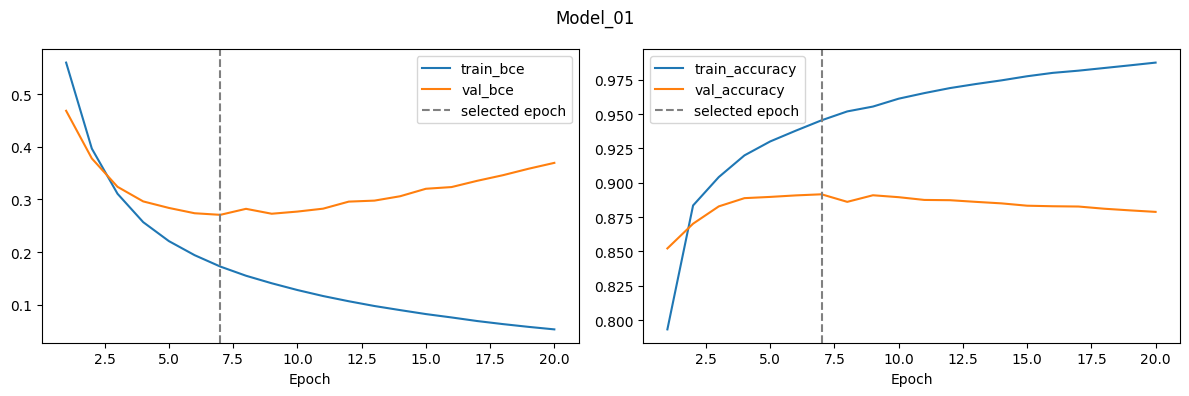

In [21]:
run_experiment('Model_01')
plot_learning('Model_01')


### Model_02 — another hidden layer


In [22]:
run_experiment('Model_02', hidden_units=[4, 4])


INFO: Seed set to 23
INFO:lightning.fabric.utilities.seed:Seed set to 23
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: `Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
INFO:lightning.pytorch.utilities.rank_zero:`Trainer(limit_val_batche

Output()


Model_02: {'hidden_units': [4, 4], 'activation': 'relu', 'dropout': 0.0, 'optimizer': 'rmsprop', 'lr': 0.001, 'momentum': 0.0, 'l1': 0.0, 'l2': 0.0, 'loss': 'bce', 'epochs': 20, 'batch_size': 256, 'early_stopping': False, 'patience': 3}


INFO: `Trainer.fit` stopped: `max_epochs=20` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=20` reached.


'Model_02'

### Model_02-1 — a wider hidden layer


In [23]:
run_experiment('Model_02-1', hidden_units=[16])


INFO: Seed set to 23
INFO:lightning.fabric.utilities.seed:Seed set to 23
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: `Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
INFO:lightning.pytorch.utilities.rank_zero:`Trainer(limit_val_batche

Output()


Model_02-1: {'hidden_units': [16], 'activation': 'relu', 'dropout': 0.0, 'optimizer': 'rmsprop', 'lr': 0.001, 'momentum': 0.0, 'l1': 0.0, 'l2': 0.0, 'loss': 'bce', 'epochs': 20, 'batch_size': 256, 'early_stopping': False, 'patience': 3}


INFO: `Trainer.fit` stopped: `max_epochs=20` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=20` reached.


'Model_02-1'

### Capacity comparison


,Model,Validation accuracy,Common BCE at selected epoch,Selected epoch,Epochs run,Training accuracy at selected epoch,Hidden units,Training loss,Learning rate,L1,L2,Dropout
0,Model_02-1,0.8923,0.2717,3,20,0.9320,[16],bce,0.001,0.0,0.0,0.0
1,Model_01,0.8916,0.2708,7,20,0.9455,[4],bce,0.001,0.0,0.0,0.0
2,Model_02,0.8758,0.4395,7,20,0.9627,"[4, 4]",bce,0.001,0.0,0.0,0.0


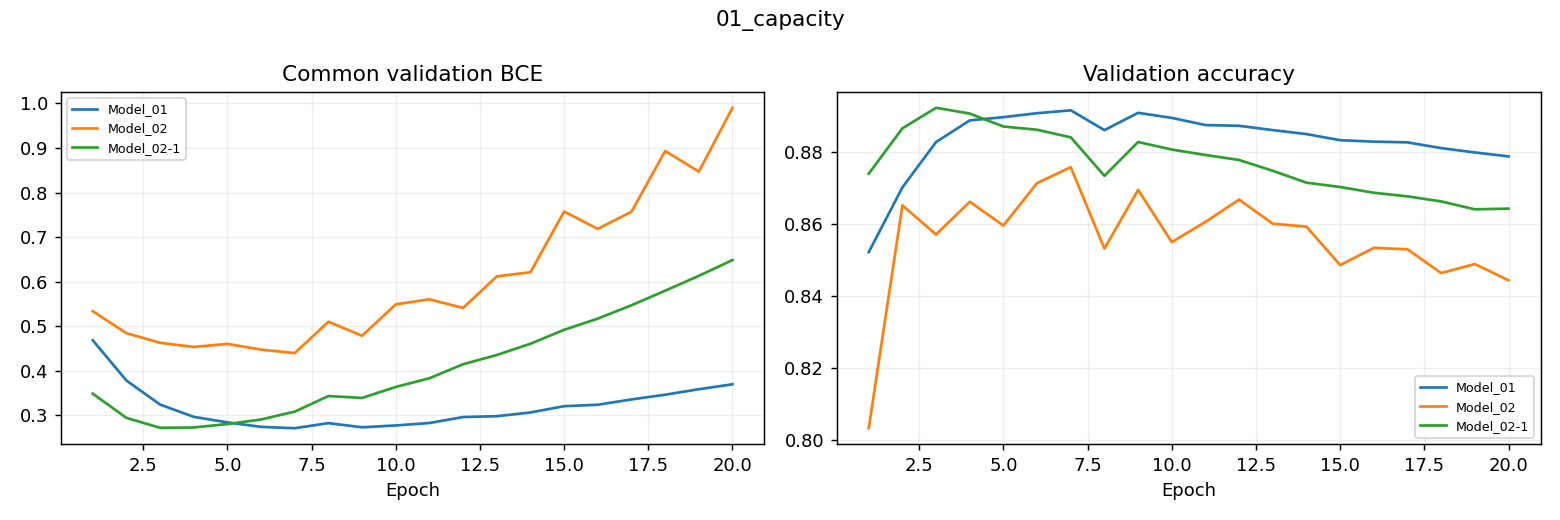

Stage winner: Model_02-1


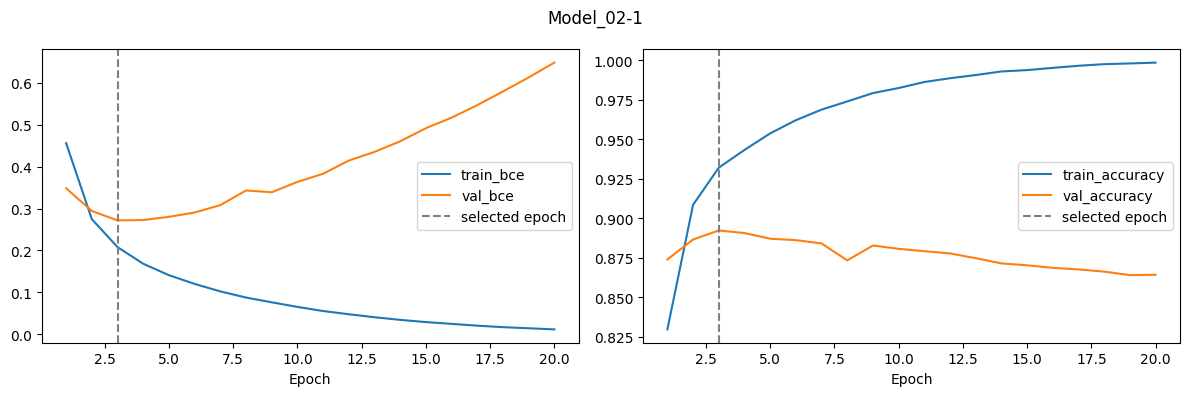

In [24]:
BEST_CAPACITY = finish_stage("01_capacity", ["Model_01", "Model_02", "Model_02-1"],
                             "Change capacity; keep the other baseline settings fixed.")
best_config = next_config(BEST_CAPACITY)
plot_learning(BEST_CAPACITY)


### Observations — capacity

All three models were able to overfit, so capacity is not a problem for this task.

- **Model_01 (4 units)** reached its best validation accuracy, 0.8916, at epoch 7. After that,
  training accuracy kept rising to almost 0.99 at epoch 20, while validation BCE increased
  from about 0.27 to 0.37 and validation accuracy slowly fell to about 0.88. This is a clear
  sign of overfitting, even with only four hidden units.
- **Model_02-1 (16 units)** reached 0.8923 at epoch 3, earlier than Model_01. By epoch 20,
  its training accuracy was almost 1.00 and its validation BCE had risen to about 0.65.
  The wider model learns faster, but it also overfits faster and more strongly.
- **Model_02 (4 → 4 units)** was the weakest model (0.8758, BCE 0.4395). Its validation
  accuracy jumped between about 0.84 and 0.88, and its validation BCE rose to nearly 1.0.
  The extra small layer made training less stable rather than better.

Model_02-1 was selected, but its advantage over Model_01 is only 0.0007, which is 7 reviews
out of 10,000. Model_01 even had a slightly lower BCE (0.2708 vs 0.2717). Therefore, this
stage shows that the network has enough capacity, but it does not prove that 16 units are
really better than 4. The main difference is how quickly the model reaches its best point
and then starts to overfit. Because the selected model overfits after only three epochs,
the next stages need to slow down training or regularise the model.

## 8. Improve model fit: learning rate

We keep the selected architecture and compare learning rates 0.001, 0.0001, 0.0005,
0.0004, 0.0003, and 0.0002. The main comparison uses 20 epochs. A learning rate that is
too large may give unstable updates; a small rate may need more training.

The winner is determined from this run. We do not assume that 0.0005 is best.


In [25]:
LR_CANDIDATES = {"Model_03": 1e-4, "Model_04": 5e-4, "Model_05": 4e-4,
                 "Model_06": 3e-4, "Model_07": 2e-4}
for name, lr in LR_CANDIDATES.items():
    run_experiment(name, **{**best_config, "lr": lr})


INFO: Seed set to 23
INFO:lightning.fabric.utilities.seed:Seed set to 23
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: `Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
INFO:lightning.pytorch.utilities.rank_zero:`Trainer(limit_val_batche

Output()


Model_03: {'hidden_units': [16], 'activation': 'relu', 'dropout': 0.0, 'optimizer': 'rmsprop', 'lr': 0.0001, 'momentum': 0.0, 'l1': 0.0, 'l2': 0.0, 'loss': 'bce', 'epochs': 20, 'batch_size': 256, 'early_stopping': False, 'patience': 3}


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


INFO: `Trainer.fit` stopped: `max_epochs=20` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=20` reached.


INFO: Seed set to 23
INFO:lightning.fabric.utilities.seed:Seed set to 23
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: `Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
INFO:lightning.pytorch.utilities.rank_zero:`Trainer(limit_val_batche

... (11 outputs left out)

INFO: Seed set to 23
INFO:lightning.fabric.utilities.seed:Seed set to 23
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: `Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
INFO:lightning.pytorch.utilities.rank_zero:`Trainer(limit_val_batche

Output()


Model_07: {'hidden_units': [16], 'activation': 'relu', 'dropout': 0.0, 'optimizer': 'rmsprop', 'lr': 0.0002, 'momentum': 0.0, 'l1': 0.0, 'l2': 0.0, 'loss': 'bce', 'epochs': 20, 'batch_size': 256, 'early_stopping': False, 'patience': 3}


INFO: `Trainer.fit` stopped: `max_epochs=20` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=20` reached.


### Extra check: 20, 30, and 50 epochs

At learning rate 0.0001, we also examine longer training. This is a separate comparison
with a different training budget. These runs are retained as final candidates, but they
do not decide the winner of the equal-epoch learning-rate stage.


INFO: Seed set to 23
INFO:lightning.fabric.utilities.seed:Seed set to 23
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: `Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
INFO:lightning.pytorch.utilities.rank_zero:`Trainer(limit_val_batche

Output()


Model_03-1: {'hidden_units': [16], 'activation': 'relu', 'dropout': 0.0, 'optimizer': 'rmsprop', 'lr': 0.0001, 'momentum': 0.0, 'l1': 0.0, 'l2': 0.0, 'loss': 'bce', 'epochs': 30, 'batch_size': 256, 'early_stopping': False, 'patience': 3}


INFO: `Trainer.fit` stopped: `max_epochs=30` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=30` reached.


INFO: Seed set to 23
INFO:lightning.fabric.utilities.seed:Seed set to 23
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: `Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
INFO:lightning.pytorch.utilities.rank_zero:`Trainer(limit_val_batche

Output()


Model_03-2: {'hidden_units': [16], 'activation': 'relu', 'dropout': 0.0, 'optimizer': 'rmsprop', 'lr': 0.0001, 'momentum': 0.0, 'l1': 0.0, 'l2': 0.0, 'loss': 'bce', 'epochs': 50, 'batch_size': 256, 'early_stopping': False, 'patience': 3}


INFO: `Trainer.fit` stopped: `max_epochs=50` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=50` reached.


,Model,Validation accuracy,Common BCE at selected epoch,Selected epoch,Epochs run,Training accuracy at selected epoch,Hidden units,Training loss,Learning rate,L1,L2,Dropout
0,Model_03-1,0.8921,0.2720,27,30,0.9475,[16],bce,0.0001,0.0,0.0,0.0
1,Model_03-2,0.8921,0.2720,27,50,0.9475,[16],bce,0.0001,0.0,0.0,0.0
2,Model_03,0.8919,0.2848,20,20,0.9361,[16],bce,0.0001,0.0,0.0,0.0


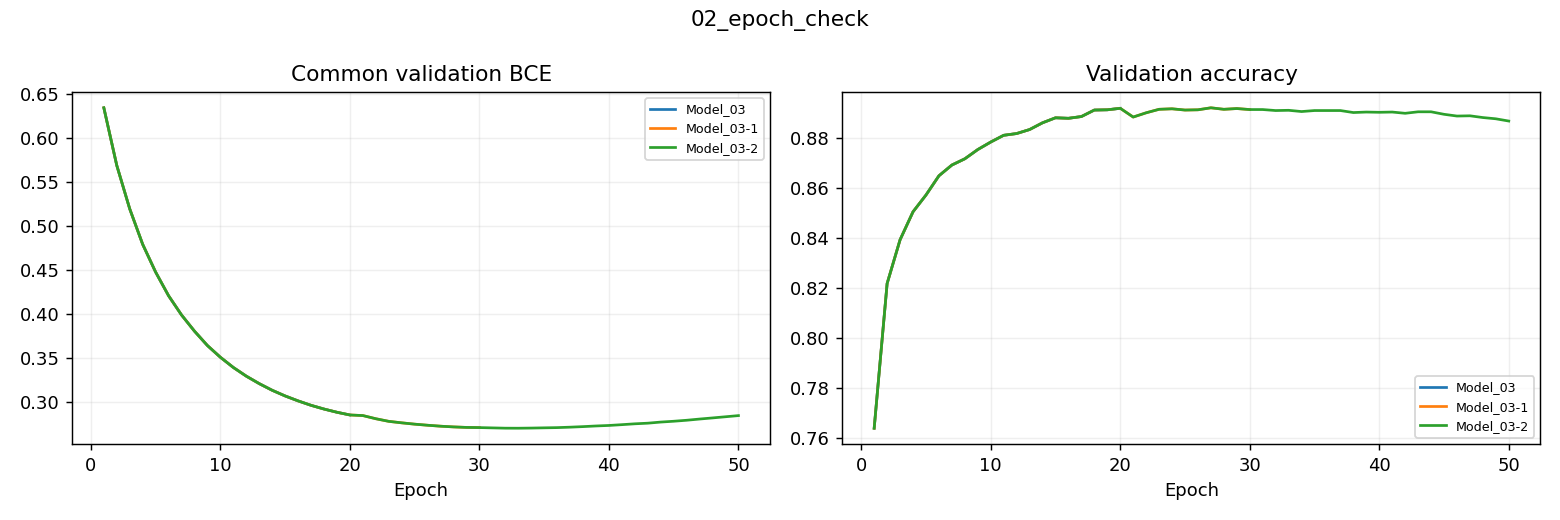

Stage winner: Model_03-1


,Model,Validation accuracy,Common BCE at selected epoch,Selected epoch,Epochs run,Training accuracy at selected epoch,Hidden units,Training loss,Learning rate,L1,L2,Dropout
0,Model_07,0.8927,0.2773,12,20,0.9416,[16],bce,0.0002,0.0,0.0,0.0
1,Model_02-1,0.8923,0.2717,3,20,0.9320,[16],bce,0.0010,0.0,0.0,0.0
2,Model_03,0.8919,0.2848,20,20,0.9361,[16],bce,0.0001,0.0,0.0,0.0
3,Model_06,0.8917,0.2720,13,20,0.9583,[16],bce,0.0003,0.0,0.0,0.0
4,Model_05,0.8913,0.2764,6,20,0.9352,[16],bce,0.0004,0.0,0.0,0.0
5,Model_04,0.8907,0.2710,6,20,0.9423,[16],bce,0.0005,0.0,0.0,0.0


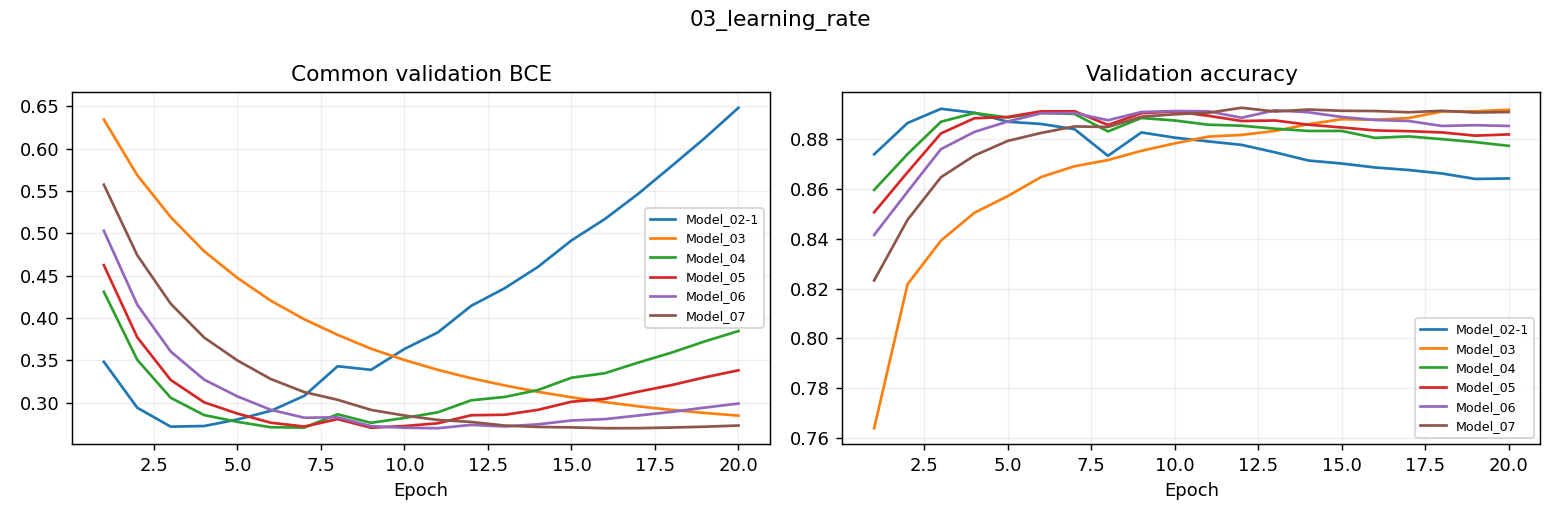

Stage winner: Model_07
Learning rate passed to regularisation: 0.0002


In [26]:
run_experiment("Model_03-1", **{**best_config, "lr": 1e-4, "epochs": 30})
run_experiment("Model_03-2", **{**best_config, "lr": 1e-4, "epochs": 50})
finish_stage("02_epoch_check", ["Model_03", "Model_03-1", "Model_03-2"],
              "Separate training-budget comparison; not used to choose the learning rate.")
BEST_LR = finish_stage("03_learning_rate", [BEST_CAPACITY, *LR_CANDIDATES],
                        "Compare learning rates with the selected architecture and equal epoch budgets.")
best_config = next_config(BEST_LR)
print("Learning rate passed to regularisation:", best_config["lr"])


### Observations — learning rate

With 16 hidden units, all six learning rates gave very similar best validation accuracy,
between 0.8907 and 0.8927. The difference is only about 20 reviews out of 10,000. The
learning rate mainly changed **when** the best epoch appeared and **how quickly** the model
overfitted after that:

| Learning rate | Best epoch | Validation accuracy | Validation BCE at epoch 20 (from the plot) |
|---|---|---|---|
| 0.001 (Model_02-1) | 3 | 0.8923 | about 0.65 |
| 0.0005 (Model_04) | 6 | 0.8907 | about 0.38 |
| 0.0004 (Model_05) | 6 | 0.8913 | about 0.34 |
| 0.0003 (Model_06) | 13 | 0.8917 | about 0.30 |
| 0.0002 (Model_07) | 12 | 0.8927 | about 0.27 |
| 0.0001 (Model_03) | 20 | 0.8919 | about 0.29, still falling |

With a high learning rate, the validation BCE goes up quickly after the best epoch, so the
result depends strongly on stopping at exactly the right time. With 0.0002, the validation
BCE stays almost flat at about 0.27–0.28 from epoch 10 to epoch 20, so training is slower
but much more stable. Model_07 (0.0002) was selected, with 0.8927 accuracy and BCE 0.2773.
It is worth noting that the lowest BCE in this stage came from Model_04 (0.2710); the
selection rule uses accuracy first, so this did not change the decision.

**Longer training at 0.0001.** At epoch 20, Model_03 was still improving. With 30 epochs,
Model_03-1 reached 0.8921 at epoch 27. The 50-epoch run, Model_03-2, selected exactly the
same checkpoint (epoch 27, accuracy 0.8921, BCE 0.2720), so there was no further
improvement after epoch 27. The identical numbers also show that training with the same
seed is reproducible. In short, 0.0001 can reach a similar accuracy, but it needs more
than twice as many epochs as 0.0002, so it has no clear advantage.

## 9. Improve generalisation

The next stages use the selected learning rate and architecture. L1 and L2 are first
tested separately against the same reference. This makes the comparisons easier to explain.
The weights are penalised on every linear layer; biases are not penalised.


### 9.1 L1 regularisation

Compare coefficients 0.001, 0.0005, and 0.00001 with the unregularised reference.
L1 can encourage some weights to become small. Stronger penalties are not always better.


INFO: Seed set to 23
INFO:lightning.fabric.utilities.seed:Seed set to 23
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: `Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
INFO:lightning.pytorch.utilities.rank_zero:`Trainer(limit_val_batche

Output()


Model_08-1: {'hidden_units': [16], 'activation': 'relu', 'dropout': 0.0, 'optimizer': 'rmsprop', 'lr': 0.0002, 'momentum': 0.0, 'l1': 0.001, 'l2': 0.0, 'loss': 'bce', 'epochs': 20, 'batch_size': 256, 'early_stopping': False, 'patience': 3}


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


INFO: `Trainer.fit` stopped: `max_epochs=20` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=20` reached.


INFO: Seed set to 23
INFO:lightning.fabric.utilities.seed:Seed set to 23
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: `Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
INFO:lightning.pytorch.utilities.rank_zero:`Trainer(limit_val_batche

... (4 outputs left out)

Output()


Model_08-3: {'hidden_units': [16], 'activation': 'relu', 'dropout': 0.0, 'optimizer': 'rmsprop', 'lr': 0.0002, 'momentum': 0.0, 'l1': 1e-05, 'l2': 0.0, 'loss': 'bce', 'epochs': 20, 'batch_size': 256, 'early_stopping': False, 'patience': 3}


INFO: `Trainer.fit` stopped: `max_epochs=20` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=20` reached.


,Model,Validation accuracy,Common BCE at selected epoch,Selected epoch,Epochs run,Training accuracy at selected epoch,Hidden units,Training loss,Learning rate,L1,L2,Dropout
0,Model_07,0.8927,0.2773,12,20,0.9416,[16],bce,0.0002,0.0000,0.0,0.0
1,Model_08-3,0.8920,0.2797,12,20,0.9379,[16],bce,0.0002,0.0000,0.0,0.0
2,Model_08-2,0.8686,0.3341,20,20,0.8767,[16],bce,0.0002,0.0005,0.0,0.0
3,Model_08-1,0.8510,0.3751,18,20,0.8587,[16],bce,0.0002,0.0010,0.0,0.0


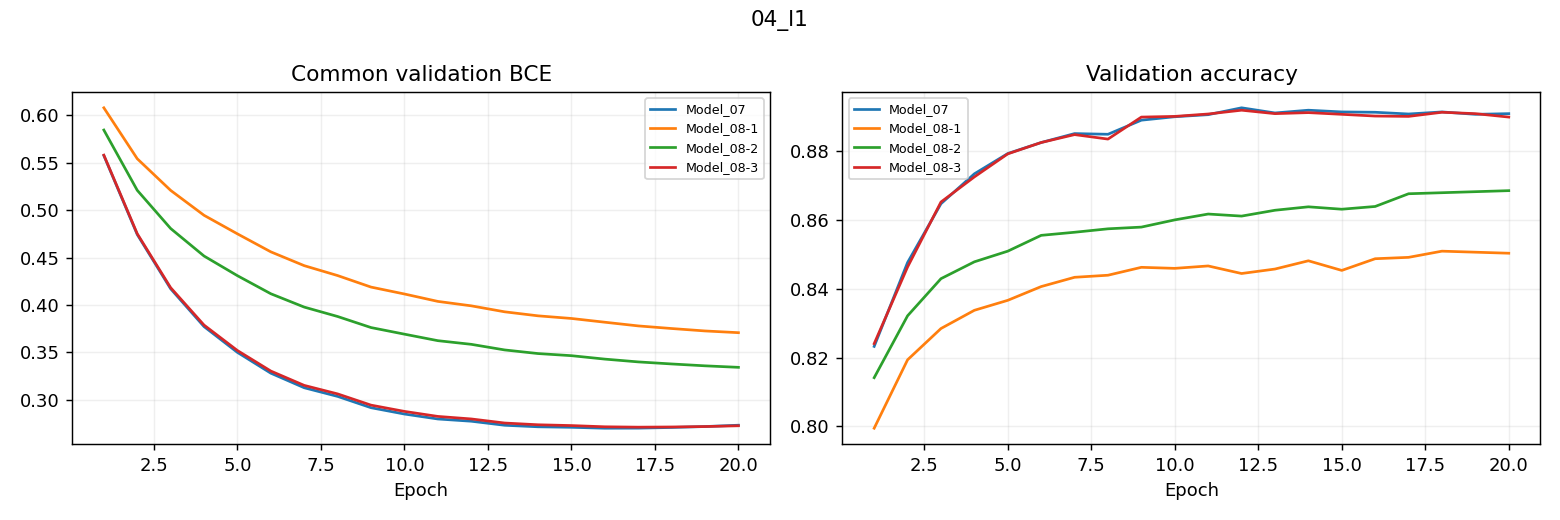

Stage winner: Model_07


In [27]:
REG_BASE = copy.deepcopy(best_config)
L1_CANDIDATES = {"Model_08-1": 1e-3, "Model_08-2": 5e-4, "Model_08-3": 1e-5}
for name, value in L1_CANDIDATES.items():
    run_experiment(name, **{**REG_BASE, "l1": value})
BEST_L1_MODEL = finish_stage("04_l1", [BEST_LR, *L1_CANDIDATES], "L1 against the same learning-rate reference.")
BEST_L1 = RESULTS[BEST_L1_MODEL]["config"]["l1"]


### Observations — L1

L1 regularisation did not improve the model. The zero-penalty reference, Model_07 (0.8927),
stayed the best, so L1 was kept at 0.

- **L1 = 0.001 (Model_08-1):** validation accuracy dropped to 0.8510, and the training
  accuracy at the selected epoch was only 0.8587. The model was underfitting, because the
  penalty was too strong for the 160,000 weights in the first layer (10,000 × 16).
- **L1 = 0.0005 (Model_08-2):** 0.8686, which is better than 0.001 but still clearly worse
  than the reference.
- **L1 = 0.00001 (Model_08-3):** 0.8920. Its curves are almost the same as the reference,
  which means the penalty was too weak to have a real effect.

A possible reason is that L1 pushes many weights to exactly zero. With multi-hot features,
each input weight belongs to one word, so a strong L1 penalty removes many useful words
from the model instead of only removing noise.

### 9.2 L2 regularisation

Compare the same three coefficient values with L1 kept at zero. L2 discourages large
weights, but its useful strength depends on the data and model.


INFO: Seed set to 23
INFO:lightning.fabric.utilities.seed:Seed set to 23
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: `Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
INFO:lightning.pytorch.utilities.rank_zero:`Trainer(limit_val_batche

Output()


Model_09-1: {'hidden_units': [16], 'activation': 'relu', 'dropout': 0.0, 'optimizer': 'rmsprop', 'lr': 0.0002, 'momentum': 0.0, 'l1': 0.0, 'l2': 0.001, 'loss': 'bce', 'epochs': 20, 'batch_size': 256, 'early_stopping': False, 'patience': 3}


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


INFO: `Trainer.fit` stopped: `max_epochs=20` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=20` reached.


INFO: Seed set to 23
INFO:lightning.fabric.utilities.seed:Seed set to 23
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: `Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
INFO:lightning.pytorch.utilities.rank_zero:`Trainer(limit_val_batche

... (4 outputs left out)

Output()


Model_09-3: {'hidden_units': [16], 'activation': 'relu', 'dropout': 0.0, 'optimizer': 'rmsprop', 'lr': 0.0002, 'momentum': 0.0, 'l1': 0.0, 'l2': 1e-05, 'loss': 'bce', 'epochs': 20, 'batch_size': 256, 'early_stopping': False, 'patience': 3}


INFO: `Trainer.fit` stopped: `max_epochs=20` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=20` reached.


,Model,Validation accuracy,Common BCE at selected epoch,Selected epoch,Epochs run,Training accuracy at selected epoch,Hidden units,Training loss,Learning rate,L1,L2,Dropout
0,Model_07,0.8927,0.2773,12,20,0.9416,[16],bce,0.0002,0.0,0.0000,0.0
1,Model_09-3,0.8925,0.2774,12,20,0.9415,[16],bce,0.0002,0.0,0.0000,0.0
2,Model_09-2,0.8908,0.2795,13,20,0.9377,[16],bce,0.0002,0.0,0.0005,0.0
3,Model_09-1,0.8892,0.2897,12,20,0.9309,[16],bce,0.0002,0.0,0.0010,0.0


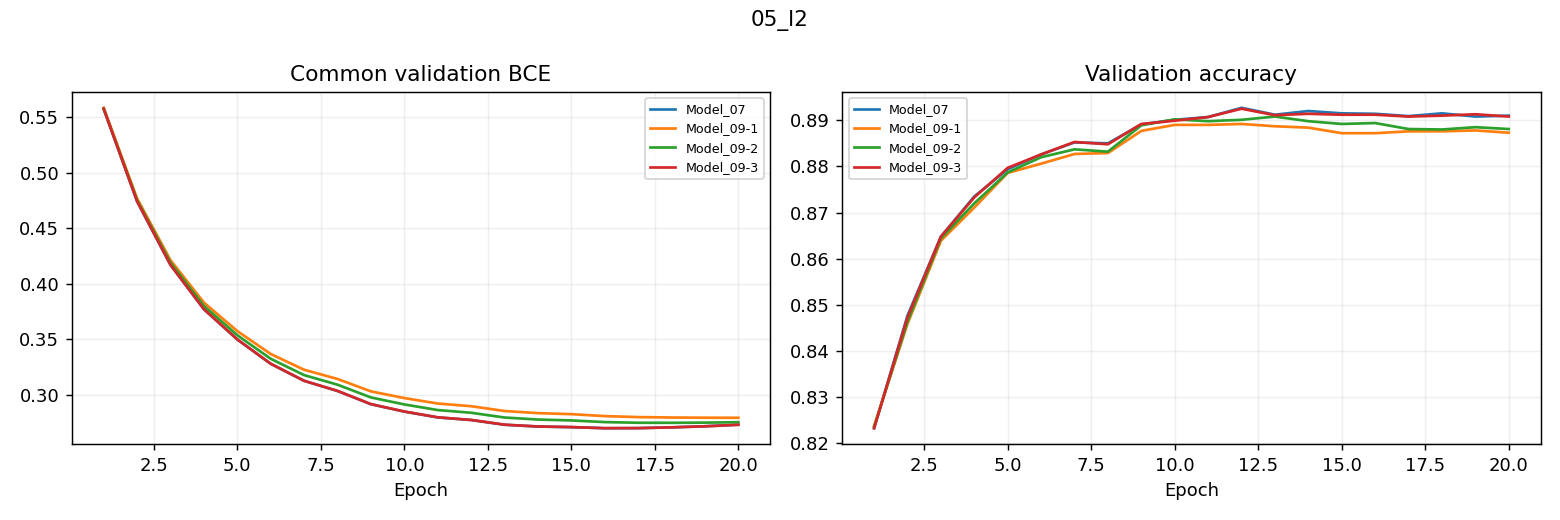

Stage winner: Model_07


In [28]:
L2_CANDIDATES = {"Model_09-1": 1e-3, "Model_09-2": 5e-4, "Model_09-3": 1e-5}
for name, value in L2_CANDIDATES.items():
    run_experiment(name, **{**REG_BASE, "l2": value})
BEST_L2_MODEL = finish_stage("05_l2", [BEST_LR, *L2_CANDIDATES], "L2 against the same learning-rate reference.")
BEST_L2 = RESULTS[BEST_L2_MODEL]["config"]["l2"]


### Observations — L2

L2 regularisation also did not improve the validation accuracy, but it was less harmful
than L1. The reference, Model_07, was kept again.

- **L2 = 0.00001 (Model_09-3):** 0.8925 with BCE 0.2774, almost identical to the reference
  (0.8927, BCE 0.2773).
- **L2 = 0.0005 (Model_09-2):** 0.8908.
- **L2 = 0.001 (Model_09-1):** 0.8892.

A stronger L2 penalty lowered the training accuracy at the selected epoch (from 0.9416 to
0.9309), so it did reduce how closely the model fitted the training data. However, the
validation accuracy did not increase. One explanation is that the learning rate of 0.0002
had already made overfitting slow: the validation BCE of the reference was almost flat
during the last ten epochs, so there was little room for a weight penalty to help.

The penalty is only part of the training objective. All the values compared here are the
common validation BCE without the penalty, so they are fair to compare.

### 9.3 L1 + L2

Combine the independently selected L1 and L2 values when both are nonzero. If one stage
kept zero, do not create a duplicate combined experiment. This is a limited sequential
search: weak individual settings might still interact, so this rule does not exhaust
every possible combination.


The selected combination would duplicate an existing zero-penalty setting; Model_10 is skipped.


,Model,Validation accuracy,Common BCE at selected epoch,Selected epoch,Epochs run,Training accuracy at selected epoch,Hidden units,Training loss,Learning rate,L1,L2,Dropout
0,Model_07,0.8927,0.2773,12,20,0.9416,[16],bce,0.0002,0.0,0.0,0.0


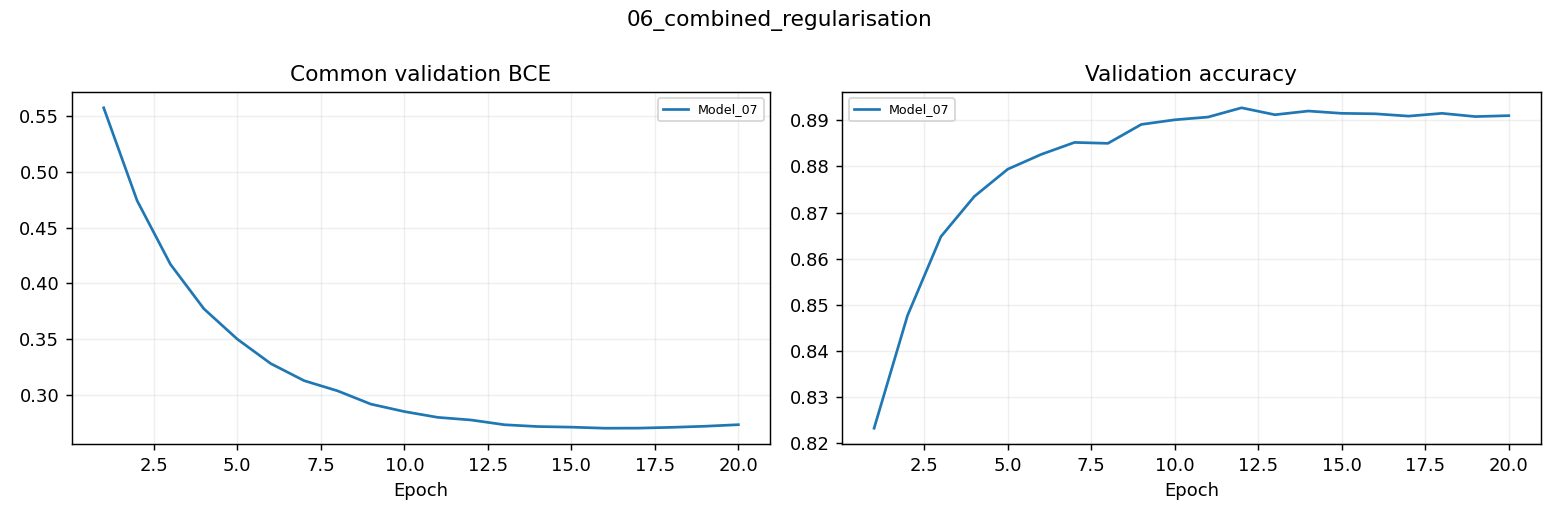

Stage winner: Model_07


In [29]:
REG_GROUP = [BEST_LR, BEST_L1_MODEL, BEST_L2_MODEL]
if BEST_L1 > 0 and BEST_L2 > 0:
    run_experiment("Model_10", **{**REG_BASE, "l1": BEST_L1, "l2": BEST_L2})
    REG_GROUP.append("Model_10")
else:
    print("The selected combination would duplicate an existing zero-penalty setting; Model_10 is skipped.")
BEST_REG = finish_stage("06_combined_regularisation", REG_GROUP, "Choose between the reference, individual penalties, and an optional combination.")
best_config = next_config(BEST_REG)


### Observations — combined regularisation

Both the L1 stage and the L2 stage selected the zero-penalty reference, so there were no
non-zero values to combine. A combined model would simply repeat Model_07, so Model_10
was skipped, and Model_07 was carried forward to the Dropout stage.

This shows one weakness of a step-by-step search. L1 and L2 were each tested only with
no Dropout. A small penalty might still be useful together with Dropout, even if it did
not help on its own. The grid search in Section 11 tests L2 = 0.0001 together with Dropout,
which partly covers this gap.

### 9.4 Dropout

Add Dropout after each hidden layer, with rates 0.5, 0.1, 0.05, and 0.01. The zero-Dropout
reference remains a candidate. Training accuracy is measured with Dropout active, while
validation runs in evaluation mode; their gap therefore needs careful interpretation.



Model_11-1: {'hidden_units': [16], 'activation': 'relu', 'dropout': 0.5, 'optimizer': 'rmsprop', 'lr': 0.0002, 'momentum': 0.0, 'l1': 0.0, 'l2': 0.0, 'loss': 'bce', 'epochs': 20, 'batch_size': 256, 'early_stopping': False, 'patience': 3}


INFO: Seed set to 23
INFO:lightning.fabric.utilities.seed:Seed set to 23
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: `Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
INFO:lightning.pytorch.utilities.rank_zero:`Trainer(limit_val_batche

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


INFO: `Trainer.fit` stopped: `max_epochs=20` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=20` reached.


INFO: Seed set to 23
INFO:lightning.fabric.utilities.seed:Seed set to 23
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: `Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
INFO:lightning.pytorch.utilities.rank_zero:`Trainer(limit_val_batche

... (8 outputs left out)

Output()


Model_11-4: {'hidden_units': [16], 'activation': 'relu', 'dropout': 0.01, 'optimizer': 'rmsprop', 'lr': 0.0002, 'momentum': 0.0, 'l1': 0.0, 'l2': 0.0, 'loss': 'bce', 'epochs': 20, 'batch_size': 256, 'early_stopping': False, 'patience': 3}


INFO: `Trainer.fit` stopped: `max_epochs=20` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=20` reached.


,Model,Validation accuracy,Common BCE at selected epoch,Selected epoch,Epochs run,Training accuracy at selected epoch,Hidden units,Training loss,Learning rate,L1,L2,Dropout
0,Model_11-1,0.8940,0.2803,15,20,0.9148,[16],bce,0.0002,0.0,0.0,0.50
1,Model_07,0.8927,0.2773,12,20,0.9416,[16],bce,0.0002,0.0,0.0,0.00
2,Model_11-2,0.8926,0.2694,16,20,0.9469,[16],bce,0.0002,0.0,0.0,0.10
3,Model_11-3,0.8926,0.2782,12,20,0.9355,[16],bce,0.0002,0.0,0.0,0.05
4,Model_11-4,0.8922,0.2775,12,20,0.9401,[16],bce,0.0002,0.0,0.0,0.01


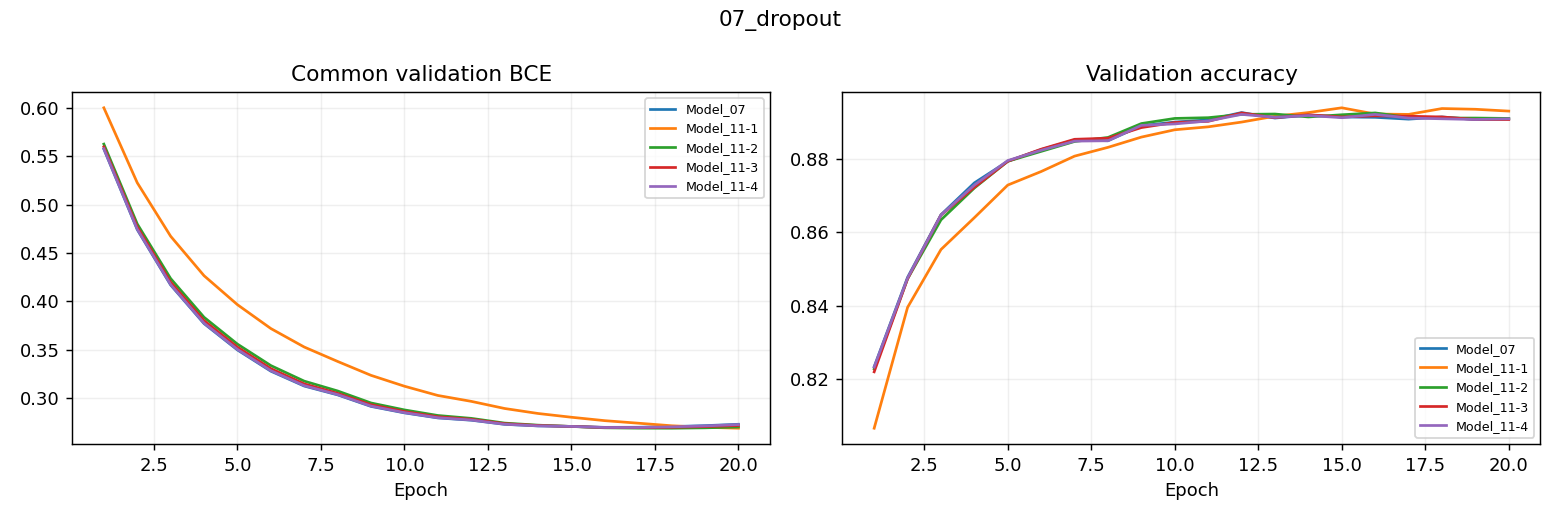

Stage winner: Model_11-1


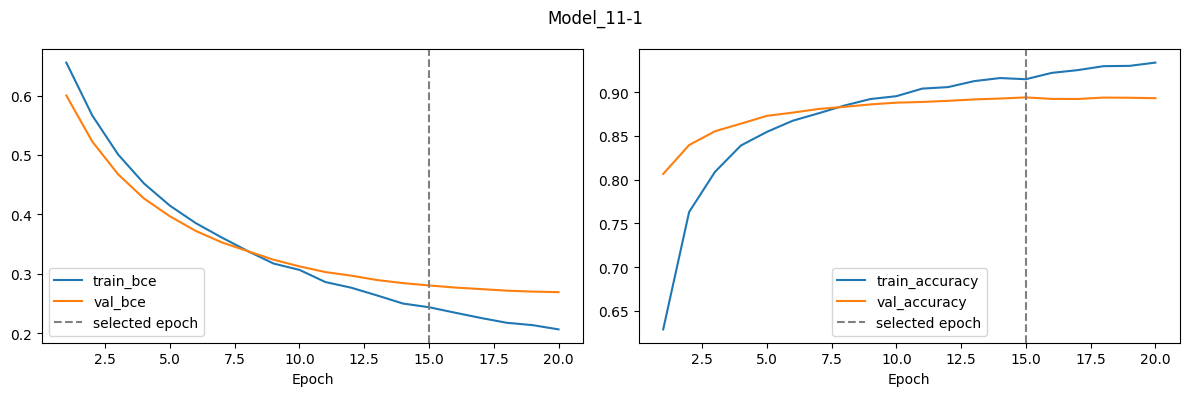

In [30]:
DROPOUT_CANDIDATES = {"Model_11-1": 0.5, "Model_11-2": 0.1, "Model_11-3": 0.05, "Model_11-4": 0.01}
for name, rate in DROPOUT_CANDIDATES.items():
    run_experiment(name, **{**best_config, "dropout": rate})
BEST_DROPOUT = finish_stage("07_dropout", [BEST_REG, *DROPOUT_CANDIDATES], "Dropout rates with the selected preceding settings.")
best_config = next_config(BEST_DROPOUT)
plot_learning(BEST_DROPOUT)


### Observations — Dropout

Dropout 0.5 (Model_11-1) gave the best validation accuracy, **0.8940** at epoch 15. This is
0.0013 higher than the reference (13 reviews out of 10,000). The smaller rates, 0.1, 0.05,
and 0.01, gave 0.8922–0.8926, which is about the same as no Dropout. Dropout 0.1 had the
lowest BCE in this stage (0.2694), so the ranking would be slightly different if BCE were
the main criterion.

The learning curves show the effect of Dropout more clearly than the accuracy numbers.
With Dropout 0.5, training accuracy starts low (about 0.63 after the first epoch) and stays
close to validation accuracy for the first eight epochs. At the selected epoch, the training
accuracy is 0.9148 and the validation accuracy is 0.8940, a gap of about 0.02. For Model_07
without Dropout, the gap at its selected epoch was about 0.05 (0.9416 vs 0.8927). The
validation BCE of Model_11-1 also keeps decreasing until epoch 20 without a clear rise.

So strong Dropout clearly reduced overfitting, even though the gain in accuracy was small.
However, the gap is not a perfect measure: training accuracy is measured while Dropout is
active, but validation accuracy is measured without Dropout. Also, a difference of 13 reviews
from one seed could partly be random, which is why the finalists are checked with more
seeds in Section 12.

### 9.5 Early stopping

Model_12 allows up to 50 epochs and stops after three validation checks without a higher
accuracy. The selected checkpoint is the earliest epoch with the highest accuracy.
The regular reference trained for 20 epochs, so this comparison changes the allowed
training budget as well as the stopping rule. It is not an isolated test of one factor.

We select the better observed setting here. For the next equal-budget comparisons, its
network and optimiser settings are retained, but epochs return to 20 and early stopping
is disabled. A fresh reference is trained for that comparison.


INFO: Seed set to 23
INFO:lightning.fabric.utilities.seed:Seed set to 23
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: `Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
INFO:lightning.pytorch.utilities.rank_zero:`Trainer(limit_val_batche

Output()


Model_12: {'hidden_units': [16], 'activation': 'relu', 'dropout': 0.5, 'optimizer': 'rmsprop', 'lr': 0.0002, 'momentum': 0.0, 'l1': 0.0, 'l2': 0.0, 'loss': 'bce', 'epochs': 50, 'batch_size': 256, 'early_stopping': True, 'patience': 3}


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


,Model,Validation accuracy,Common BCE at selected epoch,Selected epoch,Epochs run,Training accuracy at selected epoch,Hidden units,Training loss,Learning rate,L1,L2,Dropout
0,Model_11-1,0.894,0.2803,15,20,0.9148,[16],bce,0.0002,0.0,0.0,0.5
1,Model_12,0.894,0.2803,15,18,0.9148,[16],bce,0.0002,0.0,0.0,0.5


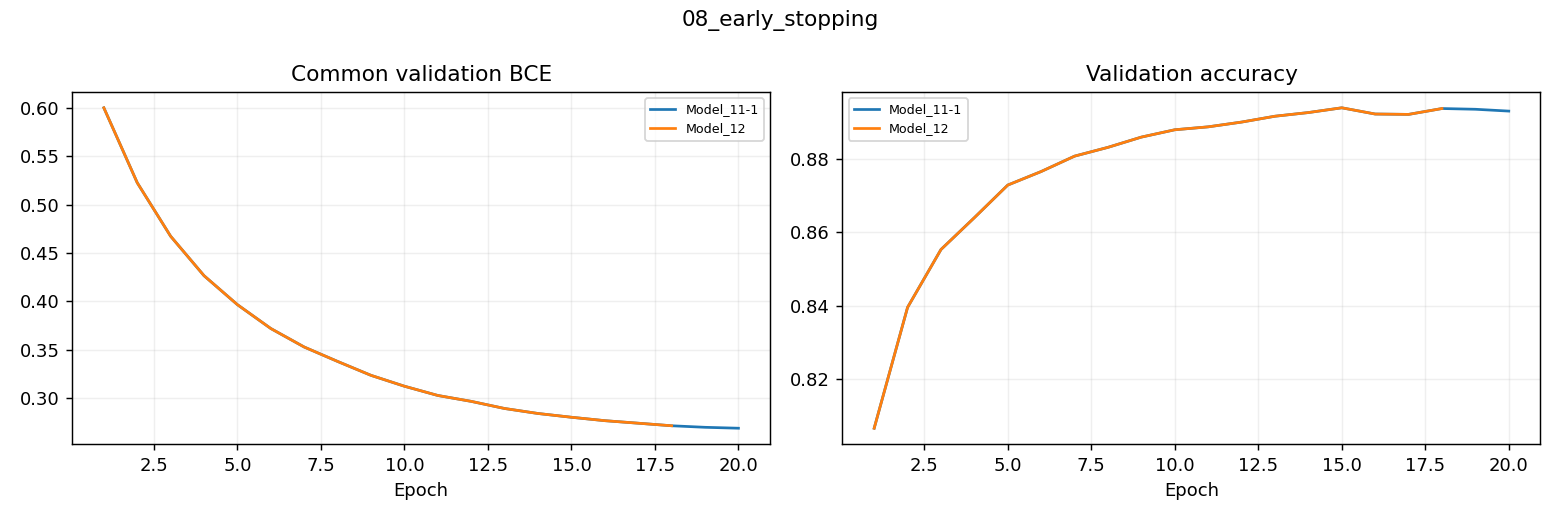

Stage winner: Model_11-1


In [31]:
run_experiment("Model_12", **{**best_config, "epochs": 50, "early_stopping": True, "patience": 3})
BEST_STOPPING = finish_stage("08_early_stopping", [BEST_DROPOUT, "Model_12"], "Stopping strategy and maximum budget both differ.")
best_config = next_config(BEST_STOPPING)


### Observations — early stopping

Model_12 used the same settings as Model_11-1, with a maximum of 50 epochs and patience 3.
Its best validation accuracy appeared at epoch 15 (0.8940). Epochs 16, 17, and 18 did not
improve on it, so training stopped at **epoch 18**. The selected checkpoint is identical to
Model_11-1 (same epoch, same accuracy, and same BCE 0.2803), because the first 18 epochs
are the same training run with the same seed. Since the two models were tied, the name
tie-break kept Model_11-1.

Early stopping did not improve accuracy here, but it saved training time: 18 epochs instead
of 20, and far fewer than the 50 epochs that were allowed. This becomes more useful in the
grid search, where each run may train for up to 50 epochs.

This is not a perfectly matched comparison, because the maximum budget (50 vs 20 epochs)
and the stopping rule both changed. Also, a patience of three epochs is short. Validation
accuracy changes by very small amounts between epochs, so the stopping point can depend
partly on random variation.

## 10. Further comparisons

We now compare loss, activation, momentum, optimiser, and depth. A fresh 20-epoch
reference uses the settings selected so far (16 ReLU units, Dropout 0.5, RMSprop with
learning rate 0.0002). Each alternative starts from that same reference, rather than
combining several untested changes in sequence.

MSE still uses common validation BCE as the accuracy tie-break. The matched-learning-rate
Adam run (Model_16-2, learning rate 0.0002) isolates the optimiser choice more closely.
Because the reference uses 0.0002, Adam at 0.001 (Model_16-1) also changes the learning
rate. The deeper Tanh model changes both depth and activation, so its result cannot be
attributed to only one factor.

INFO: Seed set to 23
INFO:lightning.fabric.utilities.seed:Seed set to 23
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: `Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
INFO:lightning.pytorch.utilities.rank_zero:`Trainer(limit_val_batche

Output()


Reference_20: {'hidden_units': [16], 'activation': 'relu', 'dropout': 0.5, 'optimizer': 'rmsprop', 'lr': 0.0002, 'momentum': 0.0, 'l1': 0.0, 'l2': 0.0, 'loss': 'bce', 'epochs': 20, 'batch_size': 256, 'early_stopping': False, 'patience': 3}


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


INFO: `Trainer.fit` stopped: `max_epochs=20` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=20` reached.


INFO: Seed set to 23
INFO:lightning.fabric.utilities.seed:Seed set to 23
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: `Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
INFO:lightning.pytorch.utilities.rank_zero:`Trainer(limit_val_batche

... (27 outputs left out)

Output()


Model_17-2: {'hidden_units': [16, 4], 'activation': 'tanh', 'dropout': 0.5, 'optimizer': 'rmsprop', 'lr': 0.0002, 'momentum': 0.0, 'l1': 0.0, 'l2': 0.0, 'loss': 'bce', 'epochs': 20, 'batch_size': 256, 'early_stopping': False, 'patience': 3}


INFO: `Trainer.fit` stopped: `max_epochs=20` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=20` reached.


,Model,Validation accuracy,Common BCE at selected epoch,Selected epoch,Epochs run,Training accuracy at selected epoch,Hidden units,Training loss,Learning rate,L1,L2,Dropout
0,Reference_20,0.8940,0.2803,15,20,0.9148,[16],bce,0.0002,0.0,0.0,0.5
1,Model_14,0.8939,0.2661,18,20,0.9424,[16],bce,0.0002,0.0,0.0,0.5
2,Model_13,0.8939,0.2908,15,20,0.9223,[16],mse,0.0002,0.0,0.0,0.5
3,Model_15-2,0.8927,0.2687,10,20,0.9268,[16],bce,0.0002,0.0,0.0,0.5
4,Model_15-1,0.8918,0.2694,3,20,0.9206,[16],bce,0.0002,0.0,0.0,0.5
5,Model_17-2,0.8913,0.3034,15,20,0.9049,"[16, 4]",bce,0.0002,0.0,0.0,0.5
6,Model_16-1,0.8911,0.2727,4,20,0.9219,[16],bce,0.0010,0.0,0.0,0.5
7,Model_16-2,0.8910,0.2859,14,20,0.9231,[16],bce,0.0002,0.0,0.0,0.5
8,Model_17-1,0.8863,0.3418,20,20,0.7983,"[16, 4]",bce,0.0002,0.0,0.0,0.5


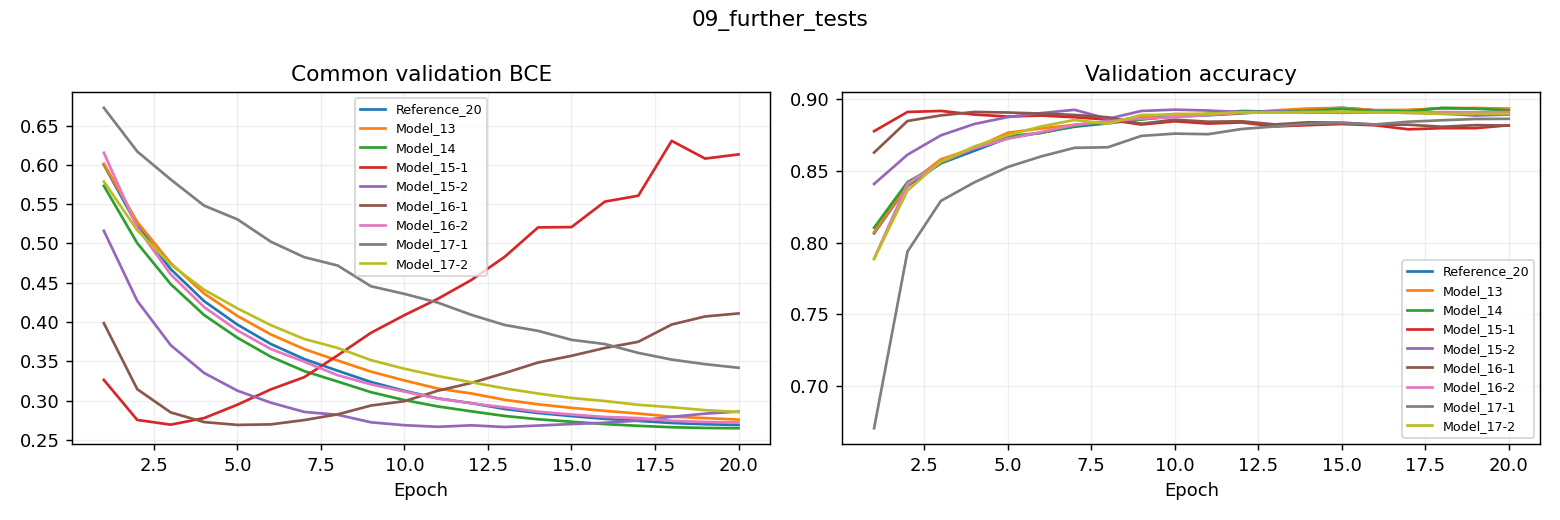

Stage winner: Reference_20


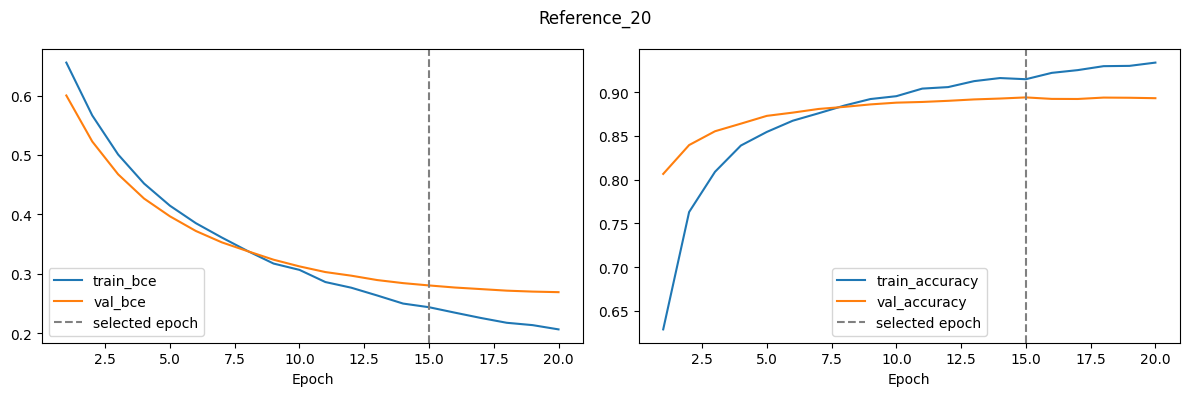

In [32]:
FURTHER_BASE = copy.deepcopy(best_config)
run_experiment("Reference_20", **FURTHER_BASE)
FURTHER_CASES = {
    "Model_13": {"loss": "mse"},
    "Model_14": {"activation": "tanh"},
    "Model_15-1": {"optimizer": "rmsprop", "momentum": 0.9},
    "Model_15-2": {"optimizer": "rmsprop", "momentum": 0.5},
    "Model_16-1": {"optimizer": "adam", "lr": 0.001, "momentum": 0.0},
    "Model_16-2": {"optimizer": "adam", "momentum": 0.0},
    "Model_17-1": {"hidden_units": FURTHER_BASE["hidden_units"] + [4]},
    "Model_17-2": {"hidden_units": FURTHER_BASE["hidden_units"] + [4], "activation": "tanh"},
}
for name, changes in FURTHER_CASES.items():
    run_experiment(name, **{**FURTHER_BASE, **changes})
BEST_FURTHER = finish_stage("09_further_tests", ["Reference_20", *FURTHER_CASES],
                            "Shared 20-epoch reference; some named alternatives change two factors.")
best_config = next_config(BEST_FURTHER)
plot_learning(BEST_FURTHER)


### Observations — further comparisons

Reference_20 used the same settings as Model_11-1 and gave exactly the same result again
(0.8940), matching the earlier validation accuracy with this seed. None of the eight
alternatives beat it in validation accuracy, although some were very close.

- **MSE loss (Model_13):** 0.8939, one fewer correct validation prediction than the reference (0.8940), but a higher common BCE
  (0.2908 vs 0.2803). MSE trains the model to reduce squared error, not log loss, so its
  probabilities are less suitable when they are judged by BCE. It gave no benefit for this
  classification task.
- **Tanh (Model_14):** 0.8939 and the lowest common BCE in this stage (0.2661). Its accuracy
  is effectively equal to ReLU, but its probability estimates were slightly better.
- **Momentum 0.9 (Model_15-1):** the best accuracy (0.8918) appeared already at epoch 3.
  After that, the validation BCE rose sharply to about 0.61. A large momentum makes the
  updates much bigger, so it behaves like a high learning rate and overfits quickly.
  **Momentum 0.5 (Model_15-2)** was more moderate: 0.8927 at epoch 10.
- **Adam (Model_16):** with learning rate 0.001, Adam reached 0.8911 at epoch 4, and then its
  BCE rose to about 0.41. With the same learning rate as the reference (0.0002), Adam reached
  0.8910 at epoch 14 with smooth curves. In this matched comparison, RMSprop was slightly
  better (by 0.0030).
- **Deeper ReLU network (Model_17-1, 16 → 4 units):** the weakest result, 0.8863, with only
  0.7983 training accuracy at its selected epoch. Dropout 0.5 is also applied after the new
  four-unit layer, so on average two of its four units are switched off at each step. This
  makes training very difficult, and the model was still underfitting at epoch 20.
  The Tanh version (Model_17-2) reached 0.8913, but it changes two factors at once.

The comparisons that change only one factor are Model_13, Model_14, Model_15-1, Model_15-2,
Model_16-2, and Model_17-1. Model_16-1 changes both the optimiser and the learning rate, and
Model_17-2 changes both depth and activation.

Overall, the simple reference was kept. Most changes affected the speed of training or the
quality of the probabilities, rather than the final accuracy.

## 11. A small grid search

The grid is centred on the selected settings, not a fixed learning rate. It explores two
widths, three learning rates, two L2 values, and two Dropout values: 24 combinations.
In this run, the values were:

- hidden units: 16 or 32
- learning rate: 0.0001, 0.0002, or 0.0004
- L2: 0 or 0.0001
- Dropout: 0.5 or 0

Other settings are carried forward. scikit-learn builds the combinations; Lightning
trains each model for up to 50 epochs with early stopping.

This can reveal some interactions missed by one-factor comparisons, but it is still a
small local search, not evidence of a global optimum. Its larger maximum training budget
also differs from most earlier comparisons. Smoke mode checks only two grid entries.

INFO: Seed set to 23
INFO:lightning.fabric.utilities.seed:Seed set to 23
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: `Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
INFO:lightning.pytorch.utilities.rank_zero:`Trainer(limit_val_batche

Output()


Grid_01: {'hidden_units': [16], 'activation': 'relu', 'dropout': 0.5, 'optimizer': 'rmsprop', 'lr': 0.0001, 'momentum': 0.0, 'l1': 0.0, 'l2': 0.0, 'loss': 'bce', 'epochs': 50, 'batch_size': 256, 'early_stopping': True, 'patience': 3}


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


INFO: Seed set to 23
INFO:lightning.fabric.utilities.seed:Seed set to 23
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: `Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
INFO:lightning.pytorch.utilities.rank_zero:`Trainer(limit_val_batche

Output()

... (62 outputs left out)

INFO: Seed set to 23
INFO:lightning.fabric.utilities.seed:Seed set to 23
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: `Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
INFO:lightning.pytorch.utilities.rank_zero:`Trainer(limit_val_batche

Output()


Grid_24: {'hidden_units': [32], 'activation': 'relu', 'dropout': 0.0, 'optimizer': 'rmsprop', 'lr': 0.0004, 'momentum': 0.0, 'l1': 0.0, 'l2': 0.0001, 'loss': 'bce', 'epochs': 50, 'batch_size': 256, 'early_stopping': True, 'patience': 3}


,Model,Validation accuracy,Common BCE at selected epoch,Selected epoch,Epochs run,Training accuracy at selected epoch,Hidden units,Training loss,Learning rate,L1,L2,Dropout
0,Grid_05,0.8945,0.2818,15,18,0.9142,[16],bce,0.0002,0.0,0.0001,0.5
1,Grid_01,0.8944,0.2737,34,37,0.9263,[16],bce,0.0001,0.0,0.0000,0.5
2,Grid_04,0.8940,0.2803,31,34,0.9185,[16],bce,0.0001,0.0,0.0001,0.5
3,Grid_02,0.8940,0.2803,15,18,0.9148,[16],bce,0.0002,0.0,0.0000,0.5
4,Reference_20,0.8940,0.2803,15,20,0.9148,[16],bce,0.0002,0.0,0.0000,0.5
5,Grid_07,0.8938,0.2683,28,31,0.9369,[32],bce,0.0001,0.0,0.0000,0.5
6,Grid_08,0.8935,0.2684,14,17,0.9367,[32],bce,0.0002,0.0,0.0000,0.5
7,Grid_09,0.8934,0.2738,6,9,0.9240,[32],bce,0.0004,0.0,0.0000,0.5
8,Grid_03,0.8929,0.2854,7,10,0.9103,[16],bce,0.0004,0.0,0.0000,0.5
9,Grid_10,0.8928,0.2701,28,31,0.9348,[32],bce,0.0001,0.0,0.0001,0.5


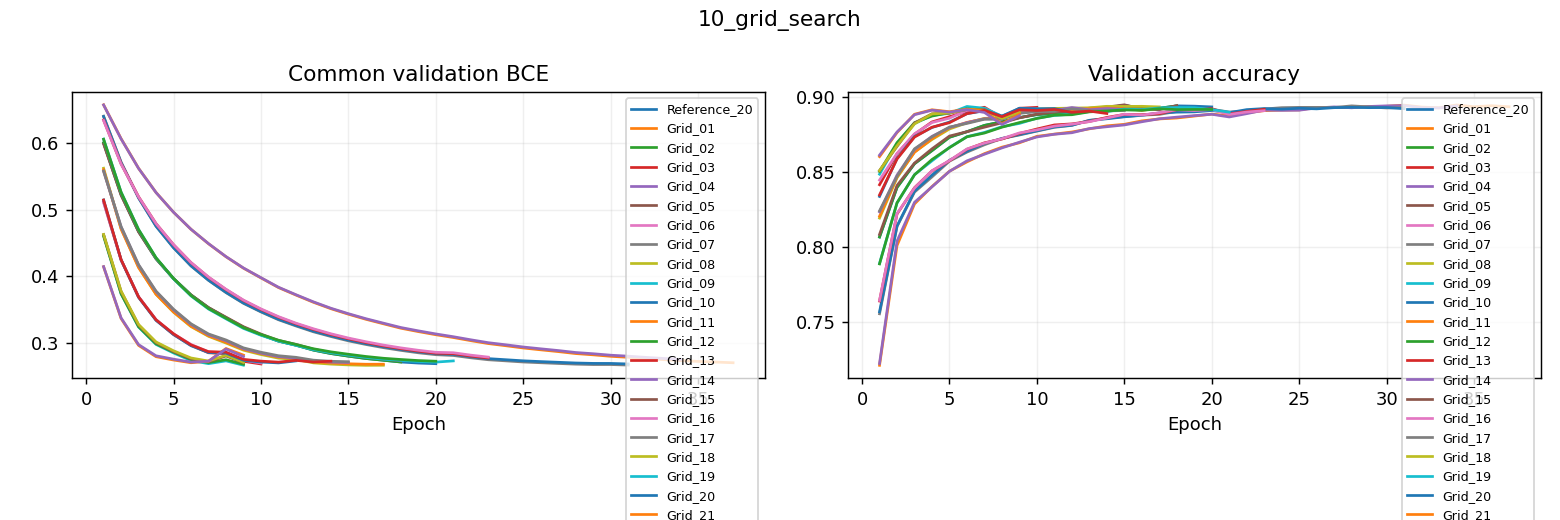

Stage winner: Grid_05


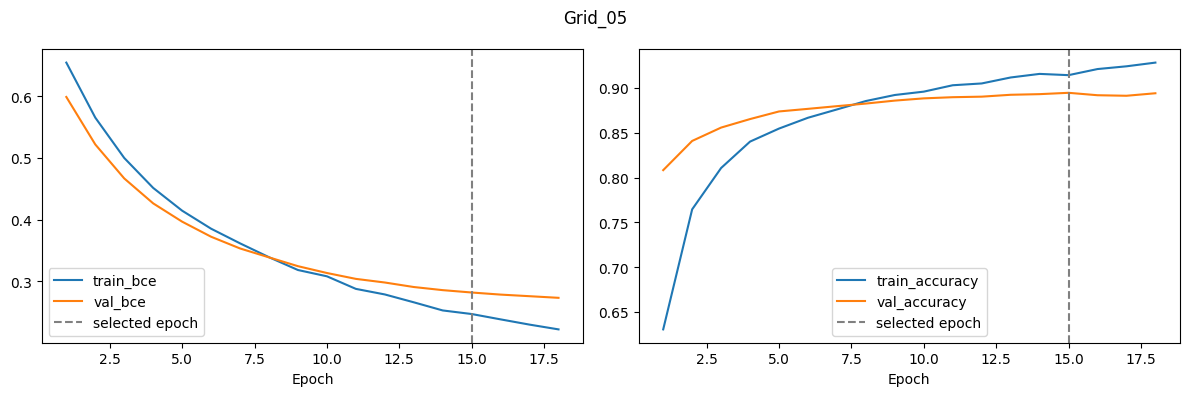

In [33]:
GRID_BASE = copy.deepcopy(best_config)
wider = GRID_BASE["hidden_units"].copy()
wider[-1] *= 2
grid = list(ParameterGrid({
    "hidden_units": [GRID_BASE["hidden_units"], wider],
    "lr": [GRID_BASE["lr"] / 2, GRID_BASE["lr"], GRID_BASE["lr"] * 2],
    "l2": [GRID_BASE["l2"], 0.0 if GRID_BASE["l2"] else 1e-4],
    "dropout": [GRID_BASE["dropout"], 0.0 if GRID_BASE["dropout"] else 0.1],
}))
assert len(grid) == 24
if RUN_MODE == "smoke":
    grid = grid[:2]
GRID_NAMES = []
for index, changes in enumerate(grid, start=1):
    name = f"Grid_{index:02d}"
    run_experiment(name, **{**GRID_BASE, **changes, "epochs": 50, "early_stopping": True})
    GRID_NAMES.append(name)
BEST_GRID = finish_stage("10_grid_search", [BEST_FURTHER, *GRID_NAMES],
                         "Adaptive local grid; grid entries allow 50 epochs with early stopping.")
plot_learning(BEST_GRID)


### Observations — grid search

The best combination was **Grid_05**: 16 units, learning rate 0.0002, L2 = 0.0001, and
Dropout 0.5. It reached 0.8945 at epoch 15 and stopped at epoch 18. This is only 0.0005
higher than Reference_20 (5 reviews out of 10,000), and its BCE was slightly higher
(0.2818 vs 0.2803). In practice, the grid search found the same setting as the manual
search, plus a very small L2 penalty.

All 24 combinations scored between 0.8913 and 0.8945, a range of only 0.0032. Some
patterns are still visible:

- **Dropout 0.5 helped.** The nine best grid entries all used Dropout 0.5. The best entry
  without Dropout (Grid_19) reached 0.8927.
- **32 units did not help.** The best 32-unit model (Grid_07) reached 0.8938, which is not
  better than the 16-unit models.
- **A higher learning rate (0.0004) stopped early** (usually after 9–10 epochs) and gave
  lower accuracy in most cases.
- **The effect of L2 = 0.0001 was not consistent.** It helped slightly at learning rate
  0.0002 (Grid_05 0.8945 vs Grid_02 0.8940), but not at 0.0001 (Grid_04 0.8940 vs Grid_01
  0.8944). This suggests that these small differences are mostly random variation.

Grid_02 has the same settings as the reference, with early stopping, and it reproduced
0.8940 exactly. Overall, the search has reached a plateau of about 0.89 validation
accuracy. The differences between the top settings are too small to trust from one seed,
which is why Section 12 repeats the two best settings with more seeds. The search was also
limited: it only explored values close to the selected settings, and it used a larger
training budget (up to 50 epochs) than most earlier stages.

## 12. Confirm a few finalists across seeds

All screening experiments use seed 23. We shortlist the best two distinct configurations
from the complete screening results, including the longer-training experiments. Each
is repeated with seeds 42 and 77. We compare mean selected-checkpoint accuracy over all
three seeds, then mean common BCE. We report the sample standard deviation as a limited
description of variation, not a confidence interval or proof of a significant difference.

The winning configuration is chosen from those means, not from its luckiest run. Its
final training length is the median selected epoch across the confirmation runs. A new,
predefined seed (2026) is used to train on all 25,000 official training reviews, without
validation or early stopping. The original small baseline is also retrained on all
25,000 reviews, using its validation-selected epoch count. Both plans are saved before
either test evaluation. These are different training sizes, so validation and final test
scores do not describe exactly the same fitted models.

Smoke mode skips confirmation and cannot test. Disabling `RUN_SEED_CONFIRMATION` in a
full run selects from one seed only; that limitation is recorded explicitly.


In [34]:
ranked_names = sorted(RESULTS, key=candidate_key)
shortlist, seen_configs = [], set()
for name in ranked_names:
    signature = json_hash(RESULTS[name]["config"])
    if signature not in seen_configs:
        shortlist.append(name)
        seen_configs.add(signature)
    if len(shortlist) == SHORTLIST_SIZE:
        break
confirmation_seeds = [SEED] + (EXTRA_SEEDS if RUN_MODE == "full" and RUN_SEED_CONFIRMATION else [])
confirmed, confirmation_rows = {}, []
for name in shortlist:
    runs = [RESULTS[name]]
    for seed in confirmation_seeds[1:]:
        runs.append(fit_trial(name, RESULTS[name]["config"], seed=seed))
    confirmed[name] = runs
    accuracies = [r["metrics"]["val_accuracy"] for r in runs]
    bces = [r["metrics"]["val_bce"] for r in runs]
    confirmation_rows.append({
        "model": name, "seeds": confirmation_seeds, "n_seeds": len(runs),
        "mean_val_accuracy": float(np.mean(accuracies)),
        "sd_val_accuracy": float(np.std(accuracies, ddof=1)) if len(runs) > 1 else None,
        "mean_common_bce": float(np.mean(bces)),
        "selected_epochs": [r["selected_epoch"] for r in runs],
    })
confirmation_rows.sort(key=lambda r: (-r["mean_val_accuracy"], r["mean_common_bce"], r["model"]))
FINAL_NAME = confirmation_rows[0]["model"]
FINAL_CONFIG = copy.deepcopy(RESULTS[FINAL_NAME]["config"])
FINAL_CONFIG.update(epochs=int(np.median([r["selected_epoch"] for r in confirmed[FINAL_NAME]])),
                    early_stopping=False)
BASELINE_FINAL_CONFIG = copy.deepcopy(RESULTS["Model_01"]["config"])
BASELINE_FINAL_CONFIG.update(epochs=RESULTS["Model_01"]["selected_epoch"], early_stopping=False)
selection = {
    "protocol_sha256": PROTOCOL_HASH, "mode": RUN_MODE,
    "selection_basis": "validation only; mean across confirmation seeds",
    "shortlist": shortlist, "confirmation": confirmation_rows,
    "confirmed_fit_ids": {name: [r["fit_id"] for r in runs] for name, runs in confirmed.items()},
    "selected_name": FINAL_NAME, "final_config": FINAL_CONFIG,
    "baseline_config": BASELINE_FINAL_CONFIG, "final_seed": FINAL_SEED,
    "threshold": 0.5, "positive_rule": "probability > threshold",
    "final_training_rows": 25_000, "historical_test_exposure": True,
}
fixed_record(RUN_DIR / "selection.json", selection)
confirmation_dir = RUN_DIR / "confirmation"
confirmation_dir.mkdir(exist_ok=True)
if (confirmation_dir / "files.json").exists():
    verify_files(confirmation_dir, read_record(confirmation_dir / "files.json"))
else:
    pd.DataFrame(confirmation_rows).to_csv(confirmation_dir / "summary.csv", index=False)
    detail_rows = [{"model": name, "seed": r["seed"], "selected_epoch": r["selected_epoch"],
                    "val_accuracy": r["metrics"]["val_accuracy"], "common_bce": r["metrics"]["val_bce"],
                    "fit_id": r["fit_id"]}
                   for name, runs in confirmed.items() for r in runs]
    pd.DataFrame(detail_rows).to_csv(confirmation_dir / "per_seed.csv", index=False)
    write_record(confirmation_dir / "files.json", inventory(confirmation_dir, exclude=("files.json",)))
display(pd.DataFrame(confirmation_rows))
print("Locked selection:", FINAL_NAME, FINAL_CONFIG)
print("Final testing is eligible:", RUN_MODE == "full" and RUN_FINAL_TEST)


INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: `Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
INFO:lightning.pytorch.utilities.rank_zero:`Trainer(limit_val_batche

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


INFO: Seed set to 77
INFO:lightning.fabric.utilities.seed:Seed set to 77
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: `Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
INFO:lightning.pytorch.utilities.rank_zero:`Trainer(limit_val_batche

Output()

INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: `Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
INFO:lightning.pytorch.utilities.rank_zero:`Trainer(limit_val_batche

Output()

INFO: Seed set to 77
INFO:lightning.fabric.utilities.seed:Seed set to 77
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: `Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
INFO:lightning.pytorch.utilities.rank_zero:`Trainer(limit_val_batche

Output()

,model,seeds,n_seeds,mean_val_accuracy,sd_val_accuracy,mean_common_bce,selected_epochs
0,Grid_05,"[23, 42, 77]",3,0.8929,0.001400,0.280240,"[15, 17, 15]"
1,Grid_01,"[23, 42, 77]",3,0.8926,0.001587,0.282784,"[34, 23, 32]"


Locked selection: Grid_05 {'hidden_units': [16], 'activation': 'relu', 'dropout': 0.5, 'optimizer': 'rmsprop', 'lr': 0.0002, 'momentum': 0.0, 'l1': 0.0, 'l2': 0.0001, 'loss': 'bce', 'epochs': 15, 'batch_size': 256, 'early_stopping': False, 'patience': 3}
Final testing is eligible: True


### Observations — seed confirmation

The two shortlisted settings were Grid_05 (learning rate 0.0002, L2 = 0.0001) and Grid_01
(learning rate 0.0001, no L2). Both use 16 units and Dropout 0.5. Across seeds 23, 42,
and 77:

| Model | Mean validation accuracy | SD | Mean common BCE | Selected epochs |
|---|---|---|---|---|
| Grid_05 | 0.8929 | 0.0014 | 0.2802 | 15, 17, 15 |
| Grid_01 | 0.8926 | 0.0016 | 0.2828 | 34, 23, 32 |

Grid_05 kept first place, so the single-seed ranking survived. However, the difference
between the two means (0.0003) is much smaller than the variation between seeds (SD about
0.0015), so the observed difference was small. Three seeds do not establish that the
settings are equivalent or that one is consistently better.

Both seed-23 scores (0.8945 and 0.8944) were higher than their three-seed means. This is
expected: when we choose the best result out of many runs, we tend to choose a run that was
also a little lucky. For these two finalists, the three-seed means on the same validation split were
closer to 0.893.

The selected epochs of Grid_05 were stable (15, 17, 15), so the median of 15 epochs is a
reasonable choice for the final training. Grid_01 needed many more epochs, and the number
changed a lot between seeds (23 to 34), because its lower learning rate makes the best
region longer and flatter. Grid_05 is therefore also the more practical choice.

## 13. Final test evaluation

This section runs automatically only in full mode with `RUN_FINAL_TEST=True`. It reads
the fixed selection, trains the selected model and baseline, and evaluates each once.
Completed evaluations are hash-checked and displayed again, not rerun. If a session
fails during evaluation, recovery can repeat evaluation of the **same checkpoint**;
the exposure record makes this visible. It is not a chance to tune the model again.

We report accuracy, positive-class precision/recall/F1, ROC AUC, common BCE, and a
confusion matrix. The prediction threshold is fixed at 0.5 before testing. Do not change
the model, threshold, or selected epoch after seeing these results and then describe
the next result as an independent test.


INFO: Seed set to 2026
INFO:lightning.fabric.utilities.seed:Seed set to 2026
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/trainer/configuration_validator.py:70: You defined a `validation_step` but have no `val_dataloader

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


INFO: `Trainer.fit` stopped: `max_epochs=15` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=15` reached.


INFO: Seed set to 2026
INFO:lightning.fabric.utilities.seed:Seed set to 2026
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Output()

... (3 outputs left out)

INFO: Seed set to 2026
INFO:lightning.fabric.utilities.seed:Seed set to 2026
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: Restoring states from the checkpoint path at /content/drive/MyDrive/IMDB_Classification_Coursework/runs/imdb_classification_v02_run01_full/fits/final/

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


,role,test_rows,accuracy,common_bce,positive_precision,positive_recall,positive_f1,roc_auc
0,selected,25000,0.8908,0.2727,0.8950,0.8856,0.8903,0.9554
1,baseline,25000,0.8855,0.2857,0.8996,0.8678,0.8834,0.9518


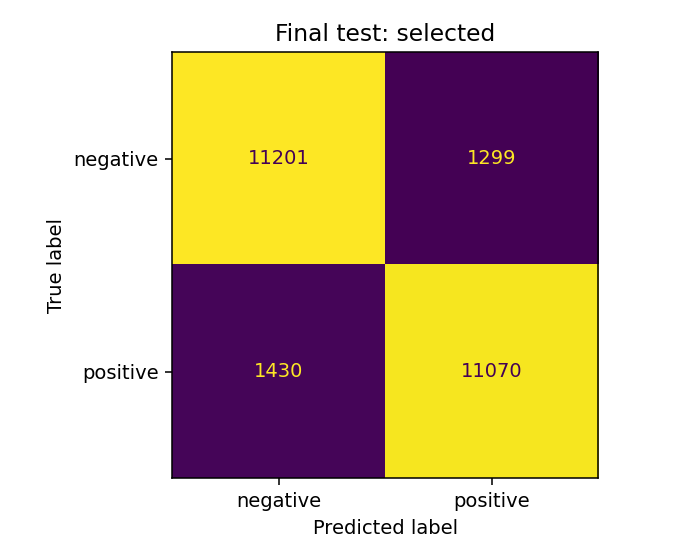

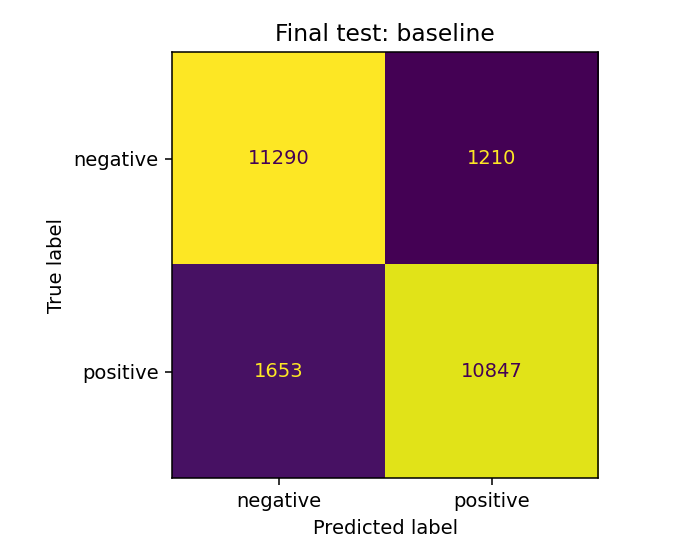

In [35]:
def evaluate_fixed_model(role, fit_result):
    folder = RUN_DIR / "final_evaluation" / role
    folder.mkdir(parents=True, exist_ok=True)
    trial_dir = child_path(RUN_DIR, fit_result["trial_dir"])
    checkpoint = child_path(trial_dir, fit_result["selected_checkpoint"])
    verify_files(trial_dir, {fit_result["selected_checkpoint"]: fit_result["checkpoint_sha256"]})
    spec = {"role": role, "fit_id": fit_result["fit_id"],
            "checkpoint_sha256": fit_result["checkpoint_sha256"],
            "selection_sha256": json_hash(selection), "source_sha256": IMDB_SHA256,
            "threshold": 0.5, "positive_rule": "probability > threshold"}
    fixed_record(folder / "spec.json", spec)
    if (folder / "complete.json").exists():
        verify_files(folder, read_record(folder / "complete.json"))
        print("Verified and reused final test:", role)
        return read_record(folder / "metrics.json")

    # Record every attempted exposure before test inference, including recovery attempts.
    exposure = {**spec, "session": SESSION_ID, "started_utc": datetime.now(timezone.utc).isoformat()}
    write_record(folder / "exposures" / f"{SESSION_ID}_{uuid.uuid4().hex[:8]}.json", exposure)
    pl.seed_everything(FINAL_SEED, workers=True)
    model = SentimentModel(fit_result["config"], fit_result["fit_id"], has_validation=False)
    trainer = pl.Trainer(logger=False, enable_checkpointing=False, **trainer_options())
    data = ReviewDataset(test_x, test_y, np.arange(len(test_y)))
    batches = trainer.predict(model, dataloaders=make_loader(data, fit_result["config"]["batch_size"]),
                              ckpt_path=str(checkpoint))
    probabilities = torch.cat(batches).numpy().astype(np.float64)
    assert probabilities.shape == test_y.shape and np.isfinite(probabilities).all()
    predictions = (probabilities > 0.5).astype(np.int64)
    report = classification_report(test_y, predictions, labels=[0, 1],
                                   target_names=["negative", "positive"], output_dict=True, zero_division=0)
    metrics = {"role": role, "test_rows": len(test_y), "accuracy": float(accuracy_score(test_y, predictions)),
               "common_bce": float(log_loss(test_y, probabilities, labels=[0, 1])),
               "positive_precision": float(report["positive"]["precision"]),
               "positive_recall": float(report["positive"]["recall"]),
               "positive_f1": float(report["positive"]["f1-score"]),
               "roc_auc": float(roc_auc_score(test_y, probabilities)), "classification_report": report,
               "fit_id": fit_result["fit_id"], "checkpoint_sha256": fit_result["checkpoint_sha256"]}
    pd.DataFrame({"shuffled_test_row": np.arange(len(test_y)), "source_test_row": test_order,
                  "true_label": test_y, "positive_probability": probabilities,
                  "predicted_label": predictions}).to_csv(folder / "predictions.csv", index=False)
    matrix = confusion_matrix(test_y, predictions, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay(matrix, display_labels=["negative", "positive"]).plot(ax=ax, colorbar=False)
    ax.set_title(f"Final test: {role}")
    fig.tight_layout()
    fig.savefig(folder / "confusion_matrix.png", dpi=140)
    plt.close(fig)
    write_record(folder / "metrics.json", metrics)
    write_record(folder / "complete.json", inventory(folder, exclude=("complete.json",)))
    del trainer, model, batches
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return metrics

FINAL_METRICS = []
if RUN_MODE == "full" and RUN_FINAL_TEST:
    assert read_record(RUN_DIR / "selection.json") == selection
    # Both configurations were locked before any call to evaluate_fixed_model.
    final_fits = {
        "selected": fit_trial("Final_selected", FINAL_CONFIG, seed=FINAL_SEED, phase="final"),
        "baseline": fit_trial("Final_baseline", BASELINE_FINAL_CONFIG, seed=FINAL_SEED, phase="final"),
    }
    for role, fit in final_fits.items():
        FINAL_METRICS.append(evaluate_fixed_model(role, fit))
    columns = ["role", "test_rows", "accuracy", "common_bce", "positive_precision", "positive_recall",
               "positive_f1", "roc_auc"]
    display(pd.DataFrame(FINAL_METRICS)[columns].round(4))
    for role in final_fits:
        display(__import__("IPython.display", fromlist=["Image"]).Image(
            filename=str(RUN_DIR / "final_evaluation" / role / "confusion_matrix.png")))
else:
    print("Final training and testing skipped. Reason:", "smoke mode" if RUN_MODE == "smoke" else "RUN_FINAL_TEST=False")


### Observations — final testing

Both models were trained on all 25,000 training reviews and then evaluated once on the
25,000 test reviews.

| Metric | Selected model | Baseline (Model_01) |
|---|---|---|
| Accuracy | **0.8908** | 0.8855 |
| Common BCE | **0.2727** | 0.2857 |
| Precision (positive) | 0.8950 | **0.8996** |
| Recall (positive) | **0.8856** | 0.8678 |
| F1 (positive) | **0.8903** | 0.8834 |
| ROC AUC | **0.9554** | 0.9518 |

On this test set, the selected model classified 134 more reviews correctly than the
baseline, but its positive-class precision was slightly lower.

The confusion matrices show where this improvement comes from:

| | True negatives | False positives | False negatives | True positives |
|---|---|---|---|---|
| Selected | 11,201 | 1,299 | 1,430 | 11,070 |
| Baseline | 11,290 | 1,210 | 1,653 | 10,847 |

The selected model missed 223 fewer positive reviews, but it also made 89 more false
positive predictions. The baseline is more careful about predicting "positive", which is
why its precision is higher but its recall is lower. Both models make more mistakes on
positive reviews than on negative reviews (false negatives > false positives), so at the
0.5 threshold they both have a slight tendency to predict "negative".

The test accuracy of the selected model (0.8908) is a little lower than its mean validation
accuracy (0.8929). The final model was trained on 25,000 reviews rather than 15,000, so this gap
does not isolate the effect of selecting models on the validation set.

The observed gain in accuracy was about half a percentage point. No formal significance test was run.
Also, this test set was already used many times in the original coursework, so these
numbers are not a completely fresh estimate.

## 14. Save a discussion bundle

Trials and stage decisions were saved as they finished. This section adds a summary and
a ZIP containing tables, figures, settings, environment records, and integrity manifests.
It excludes model checkpoints, quarantined files, and the source review archive. The
full recovery files remain in Drive. The ZIP is for reading and reporting; it is not a
replacement for the full run directory when resuming training.

The executed notebook contains the figures and interpretation. The result bundle stores
the same run's tables as CSV files and its checked records as JSON.


In [36]:
# Each export describes this session; a validation-only rerun cannot overwrite test history.
summary_dir = SESSION_DIR / "summary"
summary_dir.mkdir(exist_ok=True)
pd.DataFrame([summary_row(n) for n in ranked_names]).to_csv(summary_dir / "screening_results.csv", index=False)
write_record(summary_dir / "stage_decisions.json", STAGES)
write_record(summary_dir / "screening_histories.json", {n: r["history"] for n, r in RESULTS.items()})
write_record(summary_dir / "final_test_status.json", {
    "requested": RUN_FINAL_TEST, "mode": RUN_MODE, "evaluated_roles": [r["role"] for r in FINAL_METRICS],
    "historical_test_exposure": True, "new_independent_test_set": False,
})
if FINAL_METRICS:
    pd.DataFrame([{k: v for k, v in row.items() if k != "classification_report"}
                  for row in FINAL_METRICS]).to_csv(summary_dir / "final_metrics.csv", index=False)

all_files = inventory(RUN_DIR, exclude=("run_files.json",))
write_record(RUN_DIR / "run_files.json", all_files)
verify_files(RUN_DIR, all_files)
bundle_path = ROOT / "runs" / f"{RUN_TAG}_{RUN_MODE}_results.zip"
bundle_files = {relative: digest for relative, digest in all_files.items()
                if "quarantine" not in Path(relative).parts
                and Path(relative).suffix.lower() in {".json", ".csv", ".png", ".txt", ".yaml"}}
bundle_files["run_files.json"] = file_hash(RUN_DIR / "run_files.json")
temporary_zip = bundle_path.with_suffix(".zip.tmp")
with zipfile.ZipFile(temporary_zip, "w", compression=zipfile.ZIP_DEFLATED) as bundle:
    for relative in sorted(bundle_files):
        bundle.write(child_path(RUN_DIR, relative), arcname=relative)
    bundle.writestr("bundle_inventory.json", json.dumps({"files": bundle_files,
        "excluded": ["checkpoints", "quarantine", "source archive"],
        "note": "Hashes cover bundled files, except this inventory itself. Run inventory also lists files not bundled."}, indent=2))
os.replace(temporary_zip, bundle_path)
print("Full run and recovery files:", RUN_DIR)
print("Discussion ZIP:", bundle_path)
print("ZIP SHA-256:", file_hash(bundle_path))
print("Also download this notebook with its outputs and your completed observations.")


Full run and recovery files: /content/drive/MyDrive/IMDB_Classification_Coursework/runs/imdb_classification_v02_run01_full
Discussion ZIP: /content/drive/MyDrive/IMDB_Classification_Coursework/runs/imdb_classification_v02_run01_full_results.zip
ZIP SHA-256: a7f0a87d8dd3b7348ae3797241a5962b2c69f6b215936b1eb3bd08879b1f070f
Also download this notebook with its outputs and your completed observations.


## 15. Conclusion

### Main findings

This study trained small fully connected neural networks to classify IMDB movie
reviews as positive or negative, using multi-hot features of the 10,000 most common words.
The final selected model has one hidden layer of 16 ReLU units, Dropout 0.5, L2 = 0.0001,
and RMSprop with a learning rate of 0.0002. It was trained for 15 epochs on all 25,000
training reviews. On the 25,000 test reviews, it reached **0.8908 accuracy**, an F1 score of
0.8903, and a ROC AUC of 0.9554.

The simple baseline (4 units, learning rate 0.001, 7 epochs) reached 0.8855 accuracy on the
same test set. Both models are far above the majority-class baseline (0.4947 on validation),
but the whole tuning process improved test accuracy by only about 0.5 percentage points.

### What changed during model development?

- **Capacity:** all models could overfit within a few epochs. A wider layer (16 units) reached
  its best point faster and then overfitted more strongly. Adding a second four-unit layer made
  training unstable and gave the lowest accuracy in that stage.
- **Learning rate:** this had the largest effect on the training behaviour, but not on the best
  accuracy. A smaller rate (0.0002) delayed overfitting and kept the validation BCE almost flat,
  so the result depended much less on the exact stopping epoch.
- **Regularisation:** L1 and L2 did not help on their own; a strong L1 penalty made the model
  underfit (0.8510). Dropout 0.5 was the most useful technique. It reduced the gap between
  training and validation accuracy from about 0.05 to about 0.02, and it gave the best
  single-seed validation accuracy before the grid search (0.8940).
- **Later comparisons:** MSE, tanh, momentum, Adam, and a deeper network did not beat the
  reference. Momentum 0.9 and Adam with learning rate 0.001 overfitted very quickly, and the
  deeper network with Dropout 0.5 underfitted. Tanh gave nearly the same accuracy with a slightly
  better BCE.
- **Grid search:** all 24 combinations scored between 0.8913 and 0.8945. The best one only added
  a small L2 penalty to the settings selected in the earlier stages.

The main lesson is that, with this representation, **how fast and how long the model trains**
(learning rate, epochs, early stopping, and Dropout) matters more than its size or the choice
of loss function. Most reasonable settings end up at about 0.89 validation accuracy.

### Reliability of the findings

Most decisions in this study were based on very small differences. Between the best settings
in each stage, validation accuracy usually differed by 0.002 or less (20 reviews or fewer out
of 10,000). This is similar to the variation between random seeds (SD about 0.0015). For
example, the two finalists differed by only 0.0003 on average across three seeds, so the observed difference was small.
These three runs do not establish equivalence. The seed confirmation also showed that the single-seed
screening scores were optimistic by about 0.0016–0.0018.

Some parts of the method make the results more trustworthy. Each run used the checkpoint with
the highest validation accuracy, and every model, including the MSE model, was also compared
with the same common BCE. The test set was not used during model selection in this run: it
was used only once for each of the two models, after their settings had been saved. Model_11-1, Model_12, Reference_20,
and Grid_02 all reached 0.8940 with the same seed despite differences in stopping rules.
Matching these scores does not establish reproducibility across devices or environments.
Finally, the test accuracy (0.8908) was close to the mean validation accuracy (0.8929).

### Limitations

- Multi-hot features lose word order and word frequency, so the model cannot properly
  understand phrases such as "not good".
- The vocabulary was inherited from the archive instead of being built from our training
  subset only. About 0.5% of validation and test reviews have encoded sequences that also
  appear in the training data.
- One validation set was used to compare about 55 configurations, which can make the
  validation results look better than they really are.
- Most experiments used only one seed; only the two finalists were repeated, with three seeds.
- The search was sequential and local. For example, L2 was tested before Dropout, and the useful
  combination of L2 and Dropout was only found in the grid search. A different order could
  have led to a different shortlist.
- Some comparisons used different training budgets (20 epochs, or up to 50 epochs with early
  stopping).
- The final models were trained on 25,000 reviews, but their number of epochs was chosen with
  15,000 reviews, so each epoch contained more updates than during development.
- The test set had already been used in the earlier coursework, so this is not a fresh,
  independent evaluation. No formal significance test was carried out.
- Hardware differences and interrupted training can affect exact reproducibility.

### Next steps

1. **Use a representation that keeps word order**, such as word embeddings with a 1D
   convolutional network or an LSTM, or at least add word pairs (bigrams) to the features.
   This would answer whether the plateau at about 0.89 is caused by the multi-hot
   representation rather than by the network settings.
2. **Use k-fold cross-validation or more seeds** for the top settings. This would show whether
   differences of 0.001–0.002 are real or only random variation.
3. **Evaluate on a new held-out set of reviews**, for example newer reviews that were never used
   before. This would give an honest estimate of performance on unseen data.
4. **Run a paired significance test**, such as McNemar's test, to check whether the difference
   between the selected model and the baseline on the test set is statistically reliable.

## Postscript: what the search can tell us

The most useful part of this study was comparing the learning curves, not only the best
scores. For example, Model_02-1 (learning rate 0.001) and Model_07 (learning rate 0.0002)
reached almost the same best accuracy (0.8923 and 0.8927). However, the validation BCE of
the first model rose to about 0.65 by epoch 20, while the second stayed at about 0.27. A
single number hides this difference, but it is important in practice, because it shows how
much the result depends on stopping at the right time.

A different order of experiments would probably change which settings reached the shortlist.
The capacity stage chose 16 units over 4 units by only 7 reviews, and every later stage started
from that choice. Similarly, L2 was tested without Dropout, and it only looked useful when it
was combined with Dropout in the grid search. However, because so many settings performed
almost equally, the order would mainly change *which* of these similar settings was selected,
not the final level of accuracy.

This study cannot tell us whether a different text representation would perform much better,
whether the very small differences between the top settings are real, or how well the model
would work on newer reviews.

In the 2023 version of this coursework, I tuned the hyperparameters by hand and felt that the
process could be automated. This time, the whole search, including the grid search and the
seed confirmation, ran automatically. Automation made the search faster and fairer, but the
results also showed its limit: when the differences are this small, a careful look at the
curves and at random variation is still needed before we can trust a "winner".

## References

- [IMDB dataset and original research](https://ai.stanford.edu/~amaas/data/sentiment/)
- [Official archive loader and token conventions](https://github.com/keras-team/keras/blob/master/keras/src/datasets/imdb.py)
- [PyTorch BCEWithLogitsLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html)
- [Lightning checkpoints](https://lightning.ai/docs/pytorch/stable/common/checkpointing_basic.html)
- [Lightning ModelCheckpoint](https://lightning.ai/docs/pytorch/stable/api/lightning.pytorch.callbacks.ModelCheckpoint.html)
- [Lightning early stopping](https://lightning.ai/docs/pytorch/stable/common/early_stopping.html)
- [TorchMetrics binary accuracy](https://lightning.ai/docs/torchmetrics/stable/classification/accuracy.html)
- [scikit-learn classification metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics)
